# NYC Affordable Housing & Yellow Taxi Activity
## Data Engineering and Visualization — Milestone 1

**Team:** ]
1.Farida Nada   16007220
2.Menna Kassem  16002792
3.Adham Sameh   16002948
4.Mariam Faraht 16001862
5.Habiba Salah  16001573
6.Abdulrahman Ahmed 16006387



**Project Question:** How does affordable housing production in NYC compare with yellow taxi pickup activity across boroughs and throughout 2024?

### Important scope note
This notebook starts with the two selected datasets:
1. **Housing:** Affordable Housing Production by Building (NYC Open Data ID `hg8x-zxpr`)
2. **Transportation:** 2024 Yellow Taxi Trip Data (NYC Open Data ID `rwwi-khbc`)

Housing records are building/project records; taxi records are individual trips. They do **not** share a direct building-level key. The planned first integration is borough-by-month or borough-by-year, using taxi-zone-to-borough mapping for taxi pickup zones. This is an aggregation-based comparison, not a record-by-record join. The official taxi-zone lookup/boundary file is a supporting geographic mapping resource, not a third analytical dataset.

**Do not write conclusions until the analysis cells have been run.** Fill in decisions and observations in the Markdown prompts throughout this notebook.

## 1. Dataset links and research rationale

- Housing dataset: https://data.cityofnewyork.us/Housing-Development/Housing-New-York-Units-by-Building/hg8x-zxpr
- Transportation dataset: https://data.cityofnewyork.us/Transportation/2024-Yellow-Taxi-Trip-Data/rwwi-khbc
- Yellow taxi field definitions: https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf
- TLC trip-record information and taxi-zone resources: https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page

The housing dataset describes buildings in affordable-housing development or preservation projects. A building may appear more than once if it has participated in multiple projects, so row counts must not automatically be interpreted as unique buildings. Taxi trip data records individual trips and includes pickup/drop-off times and taxi-zone IDs.

### Feasibility Checks

- [x] **Confirm both original datasets have at least 9 columns.** The housing dataset has 41 columns, and the original taxi dataset has 19 columns. The taxi data was aggregated into four columns for analysis.
- [x] **Confirm the housing completion-date coverage overlaps the taxi period.** Both analyses use data from 2024, using housing completion dates and taxi pickup dates.
- [x] **Identify the correct taxi-zone-to-borough lookup and document its source.** The NYC taxi-zone lookup was used to map pickup-zone IDs to boroughs. The source is documented in the [TLC trip-record and taxi-zone resources](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page) linked above.
- [x] **Choose a shared level of detail.** The main integration compares borough-level summaries, while monthly analysis compares borough-month observations.
- [x] **Record why the analysis can compare these measures, and what it cannot establish.** Both datasets contain geographic information that can be summarized by borough. The analysis identifies descriptive patterns and associations but cannot establish causation.

## 2. Imports and reproducibility

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from urllib.parse import urlencode
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 100)

HOUSING_ID = "hg8x-zxpr"
TAXI_ID = "rwwi-khbc"
SOCRATA_RESOURCE_URL = "https://data.cityofnewyork.us/resource/{}.json"

print("Pandas:", pd.__version__)

Pandas: 2.2.3


## 3. Load the housing dataset

The building dataset is relatively small compared with taxi trip data, so start by loading it in full. Check the actual column names returned by the API before writing cleaning code.

In [2]:
housing_url = f"https://data.cityofnewyork.us/api/views/{HOUSING_ID}/rows.csv?accessType=download"
housing_raw = pd.read_csv(housing_url, low_memory=False)

print("Housing shape:", housing_raw.shape)
display(housing_raw.head())
display(pd.DataFrame({"column": housing_raw.columns, "dtype": housing_raw.dtypes.astype(str)}))

Housing shape: (9551, 41)


,Project ID,Project Name,Project Start Date,Project Completion Date,Building ID,Number,Street,Borough,Postcode,BBL,BIN,Community Board,Council District,Census Tract,NTA - Neighborhood Tabulation Area,Latitude,Longitude,Latitude (Internal),Longitude (Internal),Building Completion Date,Reporting Construction Type,Extended Affordability Only,Prevailing Wage Status,Extremely Low Income Units,Very Low Income Units,Low Income Units,Moderate Income Units,Middle Income Units,Other Income Units,Studio Units,1-BR Units,2-BR Units,3-BR Units,4-BR Units,5-BR Units,6-BR+ Units,Unknown-BR Units,Counted Rental Units,Counted Homeownership Units,All Counted Units,Total Units
0,68872,177-06 WEXFORD TERRACE,06/30/2026,NaN,991637.0,177-06,WEXFORD TERRACE,Queens,11432.0,4.098350e+09,4000000.0,QN-08,24,466.0,QN06,40.713096,-73.786005,40.712656,-73.786724,NaN,New Construction,No,Non Prevailing Wage,NaN,NaN,9.0,NaN,NaN,NaN,NaN,9.0,NaN,NaN,NaN,NaN,NaN,NaN,9.0,NaN,9.0,43
1,72436,ST. NICK'S. 819 GRAND STREET,06/30/2026,NaN,1021347.0,819,GRAND STREET,Brooklyn,11211.0,3.029220e+09,3070436.0,BK-01,34,481.0,BK90,40.712050,-73.940360,40.712272,-73.940295,NaN,New Construction,No,Prevailing Wage,186.0,NaN,NaN,NaN,NaN,1.0,92.0,95.0,NaN,NaN,NaN,NaN,NaN,NaN,187.0,NaN,187.0,187
2,72449,BREMOND KING DAVIS.YR15.FY26,06/30/2026,NaN,21199.0,127,EDGECOMBE AVENUE,Manhattan,10030.0,1.020480e+09,1060911.0,MN-10,9,22102.0,MN03,40.820728,-73.945285,40.820766,-73.945581,NaN,Preservation,No,Non Prevailing Wage,12.0,13.0,NaN,NaN,NaN,NaN,NaN,5.0,20.0,NaN,NaN,NaN,NaN,NaN,25.0,NaN,25.0,25
3,72449,BREMOND KING DAVIS.YR15.FY26,06/30/2026,NaN,28145.0,602,ST NICHOLAS AVENUE,Manhattan,10030.0,1.020480e+09,1060920.0,MN-10,9,22102.0,MN03,40.820717,-73.946322,40.820591,-73.946058,NaN,Preservation,No,Non Prevailing Wage,6.0,9.0,NaN,NaN,NaN,1.0,1.0,10.0,5.0,NaN,NaN,NaN,NaN,NaN,16.0,NaN,16.0,16
4,72449,BREMOND KING DAVIS.YR15.FY26,06/30/2026,NaN,40555.0,129,WEST 133 STREET,Manhattan,10030.0,1.019180e+09,1058219.0,MN-10,9,226.0,MN03,40.813338,-73.943026,40.813568,-73.943011,NaN,Preservation,No,Non Prevailing Wage,5.0,10.0,NaN,NaN,NaN,NaN,1.0,4.0,6.0,4.0,NaN,NaN,NaN,NaN,15.0,NaN,15.0,15


,column,dtype
Project ID,Project ID,int64
Project Name,Project Name,object
Project Start Date,Project Start Date,object
Project Completion Date,Project Completion Date,object
Building ID,Building ID,float64
Number,Number,object
Street,Street,object
Borough,Borough,object
Postcode,Postcode,float64
BBL,BBL,float64


In [3]:
# 1. Display all column names
print("HOUSING DATASET COLUMNS:")
print(housing_raw.columns.tolist())

# 2. Display dataset information
print("\nDATASET INFORMATION:")
housing_raw.info()

# 3. Check missing values
print("\nMISSING VALUES:")
print(housing_raw.isnull().sum())

# 4. Check duplicate rows
print("\nDUPLICATE ROWS:")
print(housing_raw.duplicated().sum())

# 5. Display basic statistics
print("\nBASIC STATISTICS:")
display(housing_raw.describe(include="all").T)

HOUSING DATASET COLUMNS:
['Project ID', 'Project Name', 'Project Start Date', 'Project Completion Date', 'Building ID', 'Number', 'Street', 'Borough', 'Postcode', 'BBL', 'BIN', 'Community Board', 'Council District', 'Census Tract', 'NTA - Neighborhood Tabulation Area', 'Latitude', 'Longitude', 'Latitude (Internal)', 'Longitude (Internal)', 'Building Completion Date', 'Reporting Construction Type', 'Extended Affordability Only', 'Prevailing Wage Status', 'Extremely Low Income Units', 'Very Low Income Units', 'Low Income Units', 'Moderate Income Units', 'Middle Income Units', 'Other Income Units', 'Studio Units', '1-BR Units', '2-BR Units', '3-BR Units', '4-BR Units', '5-BR Units', '6-BR+ Units', 'Unknown-BR Units', 'Counted Rental Units', 'Counted Homeownership Units', 'All Counted Units', 'Total Units']

DATASET INFORMATION:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 41 columns):
 #   Column                              Non-Null Count 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Project ID,9551.0,NaN,NaN,NaN,67125.247409,8463.040347,44218.0,61418.5,68781.0,73850.5,82249.0
Project Name,9551,3979,CONFIDENTIAL,1949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Project Start Date,9551,2346,06/30/2021,141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Project Completion Date,7732,2066,06/20/2019,103,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Building ID,7602.0,NaN,NaN,NaN,582729.711655,401057.617968,375.0,117976.25,805625.5,980688.75,1022537.0
Number,9551,3154,----,1949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Street,9551,1567,----,1949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Borough,9551,5,Brooklyn,3649,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Postcode,7593.0,NaN,NaN,NaN,10780.411432,504.437572,10001.0,10453.0,11102.0,11221.0,11694.0
BBL,7530.0,NaN,NaN,NaN,2510121977.677689,972093306.509762,1000050010.0,2026850033.0,3008497502.0,3039567554.5,5080477501.0


In [4]:
# 1. Calculate missing values and percentages
missing_summary = pd.DataFrame({
    "Missing Count": housing_raw.isnull().sum(),
    "Missing Percentage": (
        housing_raw.isnull().mean() * 100
    ).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values("Missing Percentage", ascending=False)

print("COLUMNS WITH MISSING VALUES:")
display(missing_summary)

# 2. Check exact duplicate rows
print("Exact duplicate rows:", housing_raw.duplicated().sum())

# 3. Check repeated project-building combinations
print(
    "Repeated Project ID and Building ID combinations:",
    housing_raw.duplicated(
        subset=["Project ID", "Building ID"]
    ).sum()
)

# 4. Check the number of unique projects and buildings
print("Unique projects:", housing_raw["Project ID"].nunique())
print("Unique buildings:", housing_raw["Building ID"].nunique())

COLUMNS WITH MISSING VALUES:


,Missing Count,Missing Percentage
6-BR+ Units,9524,99.72
5-BR Units,9478,99.24
4-BR Units,8990,94.13
Unknown-BR Units,8862,92.79
Other Income Units,8191,85.76
Moderate Income Units,7857,82.26
Extremely Low Income Units,7470,78.21
Middle Income Units,6860,71.82
Counted Homeownership Units,6821,71.42
Studio Units,6353,66.52


Exact duplicate rows: 0
Repeated Project ID and Building ID combinations: 0
Unique projects: 5928
Unique buildings: 7478


In [5]:
# Create a separate copy for cleaning
housing_clean = housing_raw.copy()

# 1. Standardize column names
housing_clean.columns = (
    housing_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

# 2. Convert date columns to datetime
date_columns = [
    "project_start_date",
    "project_completion_date",
    "building_completion_date"
]

for column in date_columns:
    if column in housing_clean.columns:
        housing_clean[column] = pd.to_datetime(
            housing_clean[column],
            errors="coerce"
        )

# 3. Standardize borough names
if "borough" in housing_clean.columns:
    housing_clean["borough"] = (
        housing_clean["borough"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

# 4. Check the results
print("Original shape:", housing_raw.shape)
print("Cleaned shape:", housing_clean.shape)

print("\nMissing completion dates:")
print(housing_clean["project_completion_date"].isna().sum())

print("\nBorough values:")
print(housing_clean["borough"].value_counts(dropna=False))

display(housing_clean.head())

Original shape: (9551, 41)
Cleaned shape: (9551, 41)

Missing completion dates:
1819

Borough values:
borough
BROOKLYN         3649
BRONX            2630
MANHATTAN        1485
QUEENS           1342
STATEN ISLAND     445
Name: count, dtype: Int64


,project_id,project_name,project_start_date,project_completion_date,building_id,number,street,borough,postcode,bbl,bin,community_board,council_district,census_tract,nta_neighborhood_tabulation_area,latitude,longitude,latitude_internal,longitude_internal,building_completion_date,reporting_construction_type,extended_affordability_only,prevailing_wage_status,extremely_low_income_units,very_low_income_units,low_income_units,moderate_income_units,middle_income_units,other_income_units,studio_units,1_br_units,2_br_units,3_br_units,4_br_units,5_br_units,6_br_units,unknown_br_units,counted_rental_units,counted_homeownership_units,all_counted_units,total_units
0,68872,177-06 WEXFORD TERRACE,2026-06-30,NaT,991637.0,177-06,WEXFORD TERRACE,QUEENS,11432.0,4.098350e+09,4000000.0,QN-08,24,466.0,QN06,40.713096,-73.786005,40.712656,-73.786724,NaT,New Construction,No,Non Prevailing Wage,NaN,NaN,9.0,NaN,NaN,NaN,NaN,9.0,NaN,NaN,NaN,NaN,NaN,NaN,9.0,NaN,9.0,43
1,72436,ST. NICK'S. 819 GRAND STREET,2026-06-30,NaT,1021347.0,819,GRAND STREET,BROOKLYN,11211.0,3.029220e+09,3070436.0,BK-01,34,481.0,BK90,40.712050,-73.940360,40.712272,-73.940295,NaT,New Construction,No,Prevailing Wage,186.0,NaN,NaN,NaN,NaN,1.0,92.0,95.0,NaN,NaN,NaN,NaN,NaN,NaN,187.0,NaN,187.0,187
2,72449,BREMOND KING DAVIS.YR15.FY26,2026-06-30,NaT,21199.0,127,EDGECOMBE AVENUE,MANHATTAN,10030.0,1.020480e+09,1060911.0,MN-10,9,22102.0,MN03,40.820728,-73.945285,40.820766,-73.945581,NaT,Preservation,No,Non Prevailing Wage,12.0,13.0,NaN,NaN,NaN,NaN,NaN,5.0,20.0,NaN,NaN,NaN,NaN,NaN,25.0,NaN,25.0,25
3,72449,BREMOND KING DAVIS.YR15.FY26,2026-06-30,NaT,28145.0,602,ST NICHOLAS AVENUE,MANHATTAN,10030.0,1.020480e+09,1060920.0,MN-10,9,22102.0,MN03,40.820717,-73.946322,40.820591,-73.946058,NaT,Preservation,No,Non Prevailing Wage,6.0,9.0,NaN,NaN,NaN,1.0,1.0,10.0,5.0,NaN,NaN,NaN,NaN,NaN,16.0,NaN,16.0,16
4,72449,BREMOND KING DAVIS.YR15.FY26,2026-06-30,NaT,40555.0,129,WEST 133 STREET,MANHATTAN,10030.0,1.019180e+09,1058219.0,MN-10,9,226.0,MN03,40.813338,-73.943026,40.813568,-73.943011,NaT,Preservation,No,Non Prevailing Wage,5.0,10.0,NaN,NaN,NaN,NaN,1.0,4.0,6.0,4.0,NaN,NaN,NaN,NaN,15.0,NaN,15.0,15


In [6]:
# Find all columns related to housing units
unit_columns = [
    column for column in housing_clean.columns
    if "unit" in column
]

print("HOUSING UNIT COLUMNS:")
print(unit_columns)

print("\nUNIT STATISTICS:")
display(housing_clean[unit_columns].describe().T)

HOUSING UNIT COLUMNS:
['community_board', 'extremely_low_income_units', 'very_low_income_units', 'low_income_units', 'moderate_income_units', 'middle_income_units', 'other_income_units', 'studio_units', '1_br_units', '2_br_units', '3_br_units', '4_br_units', '5_br_units', '6_br_units', 'unknown_br_units', 'counted_rental_units', 'counted_homeownership_units', 'all_counted_units', 'total_units']

UNIT STATISTICS:


,count,mean,std,min,25%,50%,75%,max
extremely_low_income_units,2081.0,28.286401,44.591950,1.0,2.0,8.0,37.0,429.0
very_low_income_units,3400.0,25.495588,49.298987,1.0,3.0,7.0,21.0,453.0
low_income_units,5505.0,19.794369,40.718009,1.0,1.0,5.0,19.0,536.0
moderate_income_units,1694.0,11.573200,30.344570,1.0,1.0,3.0,8.0,454.0
middle_income_units,2691.0,16.874396,34.546943,1.0,3.0,6.0,15.0,448.0
other_income_units,1360.0,1.040441,0.488857,1.0,1.0,1.0,1.0,16.0
studio_units,3198.0,17.729518,33.381338,1.0,1.0,5.0,19.0,569.0
1_br_units,6112.0,19.019634,31.261424,1.0,2.0,6.0,20.0,312.0
2_br_units,6042.0,17.500828,29.515159,1.0,2.0,7.0,18.0,305.0
3_br_units,3429.0,10.329542,17.156613,1.0,1.0,4.0,11.0,193.0


In [7]:
# Check numeric housing unit columns
unit_columns = [
    col for col in housing_clean.columns
    if "unit" in col
]

# Count zero and negative values
for col in unit_columns:
    if pd.api.types.is_numeric_dtype(housing_clean[col]):
        print(
            f"{col}: "
            f"zeros = {(housing_clean[col] == 0).sum()}, "
            f"negative = {(housing_clean[col] < 0).sum()}"
        )

# Check the largest total-unit records
print("\nLargest total-unit records:")
display(
    housing_clean.nlargest(10, "total_units")[
        ["project_id", "project_name", "borough", "total_units",
         "all_counted_units"]
    ]
)

extremely_low_income_units: zeros = 0, negative = 0
very_low_income_units: zeros = 0, negative = 0
low_income_units: zeros = 0, negative = 0
moderate_income_units: zeros = 0, negative = 0
middle_income_units: zeros = 0, negative = 0
other_income_units: zeros = 0, negative = 0
studio_units: zeros = 0, negative = 0
1_br_units: zeros = 0, negative = 0
2_br_units: zeros = 0, negative = 0
3_br_units: zeros = 0, negative = 0
4_br_units: zeros = 0, negative = 0
5_br_units: zeros = 0, negative = 0
6_br_units: zeros = 0, negative = 0
unknown_br_units: zeros = 0, negative = 0
counted_rental_units: zeros = 0, negative = 0
counted_homeownership_units: zeros = 0, negative = 0
all_counted_units: zeros = 0, negative = 0
total_units: zeros = 0, negative = 0

Largest total-unit records:


,project_id,project_name,borough,total_units,all_counted_units
1442,76349,25 WATER STREET,MANHATTAN,1320,330.0
6902,66058,605 WEST 42ND STREET PHASE II,MANHATTAN,1175,59.0
9157,49709,605 WEST 42ND ST,MANHATTAN,1175,235.0
4533,70840,5 POINTZ LIC,QUEENS,1122,337.0
3406,71573,12 ROCKWELL PLACE,BROOKLYN,1046,227.0
9040,52241,606 WEST 57TH STREET,MANHATTAN,1028,258.0
6687,65125,WEST END TOWERS,MANHATTAN,1000,250.0
8451,59538,Fleet Project 43-25 Hunter Street (20150032),QUEENS,974,195.0
4419,72274,SVEN,QUEENS,958,288.0
1781,76312,LUMEN LIC,QUEENS,938,282.0


In [8]:
# Calculate IQR bounds for total_units
Q1 = housing_clean["total_units"].quantile(0.25)
Q3 = housing_clean["total_units"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

# Identify potential outliers
outliers = housing_clean[
    (housing_clean["total_units"] < lower_bound) |
    (housing_clean["total_units"] > upper_bound)
]

print("\nPotential outlier records:", len(outliers))

display(
    outliers[
        ["project_id", "project_name", "borough", "total_units"]
    ].sort_values("total_units", ascending=False).head(10)
)

Q1: 3.0
Q3: 45.0
IQR: 42.0
Lower bound: -60.0
Upper bound: 108.0

Potential outlier records: 1171


,project_id,project_name,borough,total_units
1442,76349,25 WATER STREET,MANHATTAN,1320
6902,66058,605 WEST 42ND STREET PHASE II,MANHATTAN,1175
9157,49709,605 WEST 42ND ST,MANHATTAN,1175
4533,70840,5 POINTZ LIC,QUEENS,1122
3406,71573,12 ROCKWELL PLACE,BROOKLYN,1046
9040,52241,606 WEST 57TH STREET,MANHATTAN,1028
6687,65125,WEST END TOWERS,MANHATTAN,1000
8451,59538,Fleet Project 43-25 Hunter Street (20150032),QUEENS,974
4419,72274,SVEN,QUEENS,958
5758,67685,601 WEST 29TH STREET,MANHATTAN,938


### Outlier Detection — Total Housing Units

The Interquartile Range (IQR) method was used to identify potential outliers in the `total_units` column. The first quartile (Q1) was 3, the third quartile (Q3) was 45, and the IQR was 42. This produced an upper bound of 108 units and a lower bound of -60 units.

A total of 1,171 records exceeded the upper bound. These records were flagged for investigation rather than automatically removed because large housing developments can legitimately contain many units. No records were deleted based solely on the IQR method.


### Housing dataset overview

The Affordable Housing Production by Building dataset contains 9,551 rows and 41 columns. Each row represents a building associated with a specific affordable-housing development or preservation project.

**Important fields:**
- `project_id`: Identifies the housing project.
- `building_id`: Identifies the building when available.
- `borough`: Identifies the NYC borough.
- `project_completion_date`: The completion date associated with the project.
- `building_completion_date`: The completion date of an individual building when available.
- `postcode`, `latitude`, and `longitude`: Provide geographic information when available.
- `total_units`: Records the total units associated with the building record.

**Missing values:** `building_id` is missing in 1,949 records, `project_completion_date` in 1,819 records, and `building_completion_date` in 1,666 records.

**Repeated records:** No repeated nonmissing project-building pairs were found in the initial check. However, a building can be associated with multiple projects, so record counts should not automatically be treated as unique-building counts.

**Outliers:** The IQR method flagged 1,171 records with more than 108 total units. These records were retained because large housing developments can legitimately contain many units.

For the 2024 analysis, `project_completion_date` identifies projects completed in 2024, while `building_completion_date` is used separately for monthly comparisons. Missing identifiers are not automatically grounds for removing a record when the fields required for an analysis are available.

In [9]:
# Save the cleaned housing dataset
housing_clean.to_csv(
    "housing_clean.csv",
    index=False
)

print("Cleaned housing dataset saved successfully.")
print("Shape:", housing_clean.shape)

# Download a copy to your computer
from google.colab import files
files.download("housing_clean.csv")

Cleaned housing dataset saved successfully.
Shape: (9551, 41)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 4. Load taxi data as an aggregate, not millions of raw trips

The 2024 taxi dataset is large. Instead of downloading all trip records into the notebook, ask the Socrata API to aggregate records by pickup month and taxi zone. This avoids a biased first-N-row sample and keeps the analysis manageable. Verify that the query succeeds and document the returned coverage.

If the API rejects a query function, use the official TLC monthly files and aggregate each month locally instead.

In [10]:
# Socrata SoQL aggregation. Pickup month is returned as a month-level date.
# $limit applies to the aggregated result, not the underlying raw trip records.
taxi_params = {
    "$select": "date_trunc_ym(tpep_pickup_datetime) AS pickup_month, PULocationID AS pickup_zone_id, count(*) AS pickup_trips, avg(trip_distance) AS mean_trip_distance",
    "$where": "tpep_pickup_datetime >= '2024-01-01T00:00:00' AND tpep_pickup_datetime < '2025-01-01T00:00:00' AND PULocationID IS NOT NULL",
    "$group": "pickup_month, pickup_zone_id",
    "$order": "pickup_month, pickup_zone_id",
    "$limit": 50000
}
taxi_api_url = SOCRATA_RESOURCE_URL.format(TAXI_ID) + "?" + urlencode(taxi_params)

taxi_zone_month = pd.read_json(taxi_api_url)
print("Taxi zone-month aggregate shape:", taxi_zone_month.shape)
display(taxi_zone_month.head())
display(taxi_zone_month.dtypes)

Taxi zone-month aggregate shape: (3104, 4)


,pickup_month,pickup_zone_id,pickup_trips,mean_trip_distance
0,2024-01-01T00:00:00.000,1,295,1.083797
1,2024-01-01T00:00:00.000,2,3,12.756667
2,2024-01-01T00:00:00.000,3,105,7.551810
3,2024-01-01T00:00:00.000,4,3568,29.954406
4,2024-01-01T00:00:00.000,6,21,3.485238


,0
pickup_month,object
pickup_zone_id,int64
pickup_trips,int64
mean_trip_distance,float64


In [11]:
# Convert pickup_month into a proper datetime
taxi_zone_month["pickup_month"] = pd.to_datetime(
    taxi_zone_month["pickup_month"],
    errors="coerce"
)

# Check the date range
print("Earliest month:", taxi_zone_month["pickup_month"].min())
print("Latest month:", taxi_zone_month["pickup_month"].max())

# Count the number of months
print(
    "Number of distinct months:",
    taxi_zone_month["pickup_month"].dt.to_period("M").nunique()
)

# Check monthly totals
monthly_trips = (
    taxi_zone_month.groupby(
        taxi_zone_month["pickup_month"].dt.to_period("M")
    )["pickup_trips"]
    .sum()
)

print("\nMonthly pickup totals:")
display(monthly_trips)

# Check missing values and duplicates
print("\nMissing values:")
print(taxi_zone_month.isnull().sum())

print(
    "\nDuplicate zone-month rows:",
    taxi_zone_month.duplicated(
        subset=["pickup_month", "pickup_zone_id"]
    ).sum()
)

Earliest month: 2024-01-01 00:00:00
Latest month: 2024-12-01 00:00:00
Number of distinct months: 12

Monthly pickup totals:


,pickup_trips
pickup_month,
2024-01,2964617
2024-02,3007533
2024-03,3582611
2024-04,3514295
2024-05,3723843
2024-06,3539170
2024-07,3076876
2024-08,2979192
2024-09,3633025



Missing values:
pickup_month          0
pickup_zone_id        0
pickup_trips          0
mean_trip_distance    0
dtype: int64

Duplicate zone-month rows: 0


### Taxi Data Overview

The 2024 Yellow Taxi Trip Data dataset was aggregated by pickup month and pickup zone using the official NYC Open Data source. The resulting aggregated dataset contains **3,104 rows and 4 columns**.

**Important fields:**
- `pickup_month`: The month in which taxi trips were recorded.
- `pickup_zone_id`: The taxi pickup zone identifier, corresponding to `PULocationID` in the original dataset.
- `pickup_trips`: The number of recorded yellow taxi pickups for each zone and month.
- `mean_trip_distance`: The average recorded trip distance for each pickup zone and month.

**Time coverage:** The aggregated data covers January through December 2024, so all 12 months are represented.

**Data quality:** The aggregated dataset contains no missing values in its four columns and no duplicate month-zone combinations. The query returned 3,104 rows, below the specified API limit of 50,000 rows, so the result does not appear to have been truncated by that limit.

**Geographic mapping:** `PULocationID` identifies the taxi pickup location using the NYC taxi-zone system. An official taxi-zone lookup was used to map these identifiers to boroughs. The lookup matched all 3,104 aggregated rows, but 36 rows were excluded from the five-borough analysis because they were outside the five NYC boroughs or lacked a usable borough assignment. The retained dataset contains 3,068 rows.

**Why pickup activity was selected:** The analysis uses pickup counts consistently because they measure recorded taxi activity originating in each zone. Pickup and drop-off counts were not combined, because doing so would mix two different types of activity.

**Unusual distance values:** Some zone-month averages were unusually high, including a maximum mean trip distance of approximately 4,755.66. These values were retained rather than automatically removed because the main analysis focuses on pickup counts. Distance-based conclusions should be treated cautiously until the unusual values are investigated further.

In [12]:
# Load the official taxi-zone lookup
zone_lookup = pd.read_csv("taxi_zone_lookup.csv")

# Inspect the dataset
print("Lookup shape:", zone_lookup.shape)

print("\nColumn names:")
print(zone_lookup.columns.tolist())

print("\nFirst five rows:")
display(zone_lookup.head())

print("\nBorough values:")
print(zone_lookup["Borough"].value_counts(dropna=False))

print("\nMissing values:")
print(zone_lookup.isnull().sum())

Lookup shape: (265, 4)

Column names:
['LocationID', 'Borough', 'Zone', 'service_zone']

First five rows:


,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone



Borough values:
Borough
Queens           69
Manhattan        69
Brooklyn         61
Bronx            43
Staten Island    20
EWR               1
Unknown           1
NaN               1
Name: count, dtype: int64

Missing values:
LocationID      0
Borough         1
Zone            1
service_zone    2
dtype: int64


In [13]:
# Make a clean copy of the taxi-zone lookup
zone_lookup_clean = zone_lookup.copy()

# Remove rows without a valid NYC borough
valid_boroughs = [
    "Bronx",
    "Brooklyn",
    "Manhattan",
    "Queens",
    "Staten Island"
]

zone_lookup_clean = zone_lookup_clean[
    zone_lookup_clean["Borough"].isin(valid_boroughs)
].copy()

# Keep only the columns needed for mapping
zone_lookup_clean = zone_lookup_clean[
    ["LocationID", "Borough", "Zone"]
]

# Rename columns to match the taxi dataset
zone_lookup_clean = zone_lookup_clean.rename(
    columns={
        "LocationID": "pickup_zone_id",
        "Borough": "taxi_borough",
        "Zone": "zone_name"
    }
)

print("Original lookup rows:", len(zone_lookup))
print("Valid NYC zone rows:", len(zone_lookup_clean))

print("\nBorough distribution:")
display(zone_lookup_clean["taxi_borough"].value_counts())

print("\nDuplicate zone IDs:")
print(zone_lookup_clean["pickup_zone_id"].duplicated().sum())

Original lookup rows: 265
Valid NYC zone rows: 262

Borough distribution:


,count
taxi_borough,
Queens,69
Manhattan,69
Brooklyn,61
Bronx,43
Staten Island,20



Duplicate zone IDs:
0


In [14]:
# Join aggregated taxi data to the zone lookup
taxi_with_borough = taxi_zone_month.merge(
    zone_lookup_clean,
    on="pickup_zone_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

# Check mapping results
print("Taxi aggregate rows:", len(taxi_zone_month))
print("Rows after mapping:", len(taxi_with_borough))

print("\nMapping status:")
display(taxi_with_borough["_merge"].value_counts())

print("\nUnmapped pickup zones:")
display(
    taxi_with_borough.loc[
        taxi_with_borough["_merge"] == "left_only",
        ["pickup_zone_id", "pickup_month", "pickup_trips"]
    ].head(10)
)

Taxi aggregate rows: 3104
Rows after mapping: 3104

Mapping status:


,count
_merge,
both,3068
left_only,36
right_only,0



Unmapped pickup zones:


,pickup_zone_id,pickup_month,pickup_trips
0,1,2024-01-01,295
258,264,2024-01-01,10361
259,265,2024-01-01,1658
260,1,2024-02-01,287
512,264,2024-02-01,9660
513,265,2024-02-01,1433
514,1,2024-03-01,372
771,264,2024-03-01,11567
772,265,2024-03-01,2081
773,1,2024-04-01,509


In [15]:
# Show all unmapped zone IDs and their pickup totals
unmapped = taxi_with_borough[
    taxi_with_borough["_merge"] == "left_only"
].copy()

print("Unmapped zone IDs:")
display(
    unmapped.groupby("pickup_zone_id", as_index=False)
    .agg(
        months=("pickup_month", "nunique"),
        total_pickups=("pickup_trips", "sum")
    )
    .sort_values("pickup_zone_id")
)

# Check whether these IDs exist in the original lookup
print("\nMatching rows in the original lookup:")
display(
    zone_lookup[
        zone_lookup["LocationID"].isin([1, 264, 265])
    ]
)

# Check total pickup activity in the unmapped records
print("\nTotal pickups in unmapped records:")
print(unmapped["pickup_trips"].sum())

Unmapped zone IDs:


,pickup_zone_id,months,total_pickups
0,1,12,5940
1,264,12,122200
2,265,12,24001



Matching rows in the original lookup:


,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
263,264,Unknown,NaN,NaN
264,265,NaN,Outside of NYC,NaN



Total pickups in unmapped records:
152141


In [16]:
# Keep records successfully mapped to one of NYC's five boroughs
taxi_clean = taxi_with_borough[
    taxi_with_borough["_merge"] == "both"
].copy()

# Remove the merge indicator; retain useful mapped fields
taxi_clean = taxi_clean.drop(columns=["_merge"])

# Verify the cleaned dataset
print("Cleaned taxi shape:", taxi_clean.shape)

print("\nBorough distribution:")
display(taxi_clean["taxi_borough"].value_counts())

print("\nMissing values:")
print(taxi_clean.isnull().sum())

print("\nDuplicate zone-month records:")
print(
    taxi_clean.duplicated(
        subset=["pickup_month", "pickup_zone_id"]
    ).sum()
)

# Save the cleaned taxi data
taxi_clean.to_csv("taxi_clean.csv", index=False)

print("\nCleaned taxi dataset saved.")

Cleaned taxi shape: (3068, 6)

Borough distribution:


,count
taxi_borough,
Queens,828
Manhattan,796
Brooklyn,732
Bronx,514
Staten Island,198



Missing values:
pickup_month          0
pickup_zone_id        0
pickup_trips          0
mean_trip_distance    0
taxi_borough          0
zone_name             0
dtype: int64

Duplicate zone-month records:
0

Cleaned taxi dataset saved.


In [17]:
# Extract year from pickup date
taxi_clean["year"] = taxi_clean["pickup_month"].dt.year

# Aggregate taxi trips by borough and year
taxi_borough_year = (
    taxi_clean
    .groupby(["taxi_borough", "year"], as_index=False)
    .agg(
        total_pickups=("pickup_trips", "sum")
    )
)

print("Taxi pickups by borough and year:")
display(taxi_borough_year)

print("\nShape:", taxi_borough_year.shape)

Taxi pickups by borough and year:


,taxi_borough,year,total_pickups
0,Bronx,2024,126556
1,Brooklyn,2024,600018
2,Manhattan,2024,36402024
3,Queens,2024,3887094
4,Staten Island,2024,1831



Shape: (5, 3)


In [18]:
# Check the housing date range
print("Earliest completion date:",
      housing_clean["project_completion_date"].min())

print("Latest completion date:",
      housing_clean["project_completion_date"].max())

# Check housing completion dates by year
print(
    housing_clean["project_completion_date"]
    .dt.year
    .value_counts()
    .sort_index()
)

# Inspect the available building identifiers
print("Missing building IDs:",
      housing_clean["building_id"].isna().sum())

print("Missing project IDs:",
      housing_clean["project_id"].isna().sum())

# Check whether a project has multiple building records
print(
    "Rows with repeated project IDs:",
    housing_clean["project_id"].duplicated().sum()
)

Earliest completion date: 2014-01-03 00:00:00
Latest completion date: 2026-08-11 00:00:00
project_completion_date
2014.0    367
2015.0    249
2016.0    404
2017.0    684
2018.0    736
2019.0    808
2020.0    481
2021.0    539
2022.0    620
2023.0    741
2024.0    869
2025.0    778
2026.0    456
Name: count, dtype: int64
Missing building IDs: 1949
Missing project IDs: 0
Rows with repeated project IDs: 3623


In [19]:
# Select housing records completed in 2024
housing_2024 = housing_clean[
    housing_clean["project_completion_date"].dt.year == 2024
].copy()

print("Housing records completed in 2024:", len(housing_2024))

# Check missing values in important columns
important_columns = [
    "project_id",
    "building_id",
    "borough",
    "project_completion_date",
    "total_units"
]

display(
    housing_2024[important_columns]
    .isnull()
    .sum()
    .rename("missing_count")
    .to_frame()
)

# Inspect repeated building IDs
print(
    "Repeated non-missing building IDs:",
    housing_2024["building_id"].dropna().duplicated().sum()
)

# Inspect the 2024 housing records
display(
    housing_2024[
        important_columns
    ].head(10)
)

Housing records completed in 2024: 869


,missing_count
project_id,0
building_id,163
borough,0
project_completion_date,0
total_units,0


Repeated non-missing building IDs: 0


,project_id,building_id,borough,project_completion_date,total_units
1394,76354,NaN,BROOKLYN,2024-12-31,1
1429,74425,85555.0,BRONX,2024-12-20,55
1441,76224,NaN,BROOKLYN,2024-12-20,1
1564,75549,25538.0,MANHATTAN,2024-12-19,53
1565,75549,805872.0,MANHATTAN,2024-12-19,56
1566,76219,NaN,QUEENS,2024-12-19,1
1567,76220,NaN,STATEN ISLAND,2024-12-19,1
1571,75051,3494.0,MANHATTAN,2024-12-18,8
1572,75051,3594.0,MANHATTAN,2024-12-18,11
1573,75051,3917.0,MANHATTAN,2024-12-18,9


In [20]:
# Inspect housing unit totals by borough for 2024
housing_by_borough_check = (
    housing_2024
    .groupby("borough", as_index=False)
    .agg(
        housing_records=("project_id", "size"),
        records_with_building_id=("building_id", "count"),
        total_units_sum=("total_units", "sum"),
        unique_projects=("project_id", "nunique")
    )
)

display(housing_by_borough_check)

# Compare project-level and building-level completion dates
print("\nProject completion dates:")
print(housing_2024["project_completion_date"].describe())

print("\nBuilding completion dates:")
display(
    housing_2024["building_completion_date"].describe()
)

,borough,housing_records,records_with_building_id,total_units_sum,unique_projects
0,BRONX,323,294,27246,179
1,BROOKLYN,304,252,10945,177
2,MANHATTAN,98,88,8165,53
3,QUEENS,121,70,4217,110
4,STATEN ISLAND,23,2,134,23



Project completion dates:
count                              869
mean     2024-07-15 02:07:35.696202496
min                2024-01-05 00:00:00
25%                2024-05-09 00:00:00
50%                2024-06-25 00:00:00
75%                2024-10-08 00:00:00
max                2024-12-31 00:00:00
Name: project_completion_date, dtype: object

Building completion dates:


,building_completion_date
count,868
mean,2024-01-19 04:18:48.110599168
min,2019-06-26 00:00:00
25%,2024-01-11 00:00:00
50%,2024-06-05 00:00:00
75%,2024-09-13 00:00:00
max,2024-12-31 00:00:00


In [21]:
# 1. Aggregate housing data by borough
housing_borough_2024 = (
    housing_2024
    .groupby("borough", as_index=False)
    .agg(
        housing_records=("project_id", "size"),
        unique_projects=("project_id", "nunique"),
        total_units_sum=("total_units", "sum"),
        records_with_building_id=("building_id", "count")
    )
)

# 2. Standardize borough names for the join
housing_borough_2024["borough"] = (
    housing_borough_2024["borough"].str.strip().str.upper()
)

taxi_borough_year["taxi_borough"] = (
    taxi_borough_year["taxi_borough"].str.strip().str.upper()
)

# 3. Keep only 2024 taxi data
taxi_2024 = taxi_borough_year[
    taxi_borough_year["year"] == 2024
].copy()

# 4. Join the two datasets by borough
integrated = housing_borough_2024.merge(
    taxi_2024,
    left_on="borough",
    right_on="taxi_borough",
    how="outer",
    validate="one_to_one",
    indicator=True
)

# 5. Inspect the integrated result
print("Integrated dataset shape:", integrated.shape)

print("\nJoin status:")
display(integrated["_merge"].value_counts())

print("\nIntegrated dataset:")
display(integrated)

print("\nMissing values:")
display(integrated.isnull().sum())

# 6. Save the integrated dataset
integrated.to_csv("integrated_housing_taxi_2024.csv", index=False)

print("\nIntegrated dataset saved successfully.")

Integrated dataset shape: (5, 9)

Join status:


,count
_merge,
both,5
left_only,0
right_only,0



Integrated dataset:


,borough,housing_records,unique_projects,total_units_sum,records_with_building_id,taxi_borough,year,total_pickups,_merge
0,BRONX,323,179,27246,294,BRONX,2024,126556,both
1,BROOKLYN,304,177,10945,252,BROOKLYN,2024,600018,both
2,MANHATTAN,98,53,8165,88,MANHATTAN,2024,36402024,both
3,QUEENS,121,110,4217,70,QUEENS,2024,3887094,both
4,STATEN ISLAND,23,23,134,2,STATEN ISLAND,2024,1831,both



Missing values:


,0
borough,0
housing_records,0
unique_projects,0
total_units_sum,0
records_with_building_id,0
taxi_borough,0
year,0
total_pickups,0
_merge,0



Integrated dataset saved successfully.


In [22]:
# 1. Check total trips before and after borough mapping
print(
    "Total trips in original taxi aggregate:",
    taxi_zone_month["pickup_trips"].sum()
)

print(
    "Total trips in mapped NYC boroughs:",
    taxi_clean["pickup_trips"].sum()
)

print(
    "Total trips excluded from borough analysis:",
    unmapped["pickup_trips"].sum()
)

# 2. Check the distribution by borough
borough_check = (
    taxi_clean.groupby("taxi_borough")
    .agg(
        total_pickups=("pickup_trips", "sum"),
        number_of_zones=("pickup_zone_id", "nunique"),
        number_of_zone_month_records=("pickup_trips", "size")
    )
    .sort_values("total_pickups", ascending=False)
)

display(borough_check)

# 3. Inspect the 10 busiest pickup zones
print("\nTop 10 pickup zones by annual trips:")

top_zones = (
    taxi_clean.groupby(
        ["pickup_zone_id", "zone_name", "taxi_borough"],
        as_index=False
    )
    .agg(total_pickups=("pickup_trips", "sum"))
    .sort_values("total_pickups", ascending=False)
    .head(10)
)

display(top_zones)

# 4. Check whether all monthly totals are preserved
print(
    "\nMonthly totals before mapping:"
)
display(
    taxi_zone_month.groupby("pickup_month")["pickup_trips"].sum()
)

print(
    "\nMonthly totals after mapping:"
)
display(
    taxi_clean.groupby("pickup_month")["pickup_trips"].sum()
)

Total trips in original taxi aggregate: 41169664
Total trips in mapped NYC boroughs: 41017523
Total trips excluded from borough analysis: 152141


,total_pickups,number_of_zones,number_of_zone_month_records
taxi_borough,,,
Manhattan,36402024,67,796
Queens,3887094,69,828
Brooklyn,600018,61,732
Bronx,126556,43,514
Staten Island,1831,20,198



Top 10 pickup zones by annual trips:


,pickup_zone_id,zone_name,taxi_borough,total_pickups
128,132,JFK Airport,Queens,1989986
233,237,Upper East Side South,Manhattan,1915438
157,161,Midtown Center,Manhattan,1914605
232,236,Upper East Side North,Manhattan,1729895
158,162,Midtown East,Manhattan,1418846
226,230,Times Sq/Theatre District,Manhattan,1391157
182,186,Penn Station/Madison Sq West,Manhattan,1362156
138,142,Lincoln Square East,Manhattan,1314690
134,138,LaGuardia Airport,Queens,1295499
166,170,Murray Hill,Manhattan,1176580



Monthly totals before mapping:


,pickup_trips
pickup_month,
2024-01-01,2964617
2024-02-01,3007533
2024-03-01,3582611
2024-04-01,3514295
2024-05-01,3723843
2024-06-01,3539170
2024-07-01,3076876
2024-08-01,2979192
2024-09-01,3633025



Monthly totals after mapping:


,pickup_trips
pickup_month,
2024-01-01,2952303
2024-02-01,2996153
2024-03-01,3568591
2024-04-01,3500938
2024-05-01,3709385
2024-06-01,3525174
2024-07-01,3064593
2024-08-01,2968218
2024-09-01,3620769


In [23]:
# Check the number of zone-month records per borough
zone_month_check = (
    taxi_clean.groupby("taxi_borough")
    .agg(
        observed_zone_months=("pickup_month", "size"),
        distinct_zones=("pickup_zone_id", "nunique"),
        total_pickups=("pickup_trips", "sum")
    )
    .reset_index()
)

display(zone_month_check)

# Check pickup totals by month and borough
monthly_borough = (
    taxi_clean.groupby(
        ["pickup_month", "taxi_borough"],
        as_index=False
    )
    .agg(total_pickups=("pickup_trips", "sum"))
)

display(
    monthly_borough.pivot(
        index="pickup_month",
        columns="taxi_borough",
        values="total_pickups"
    ).fillna(0)
)

,taxi_borough,observed_zone_months,distinct_zones,total_pickups
0,Bronx,514,43,126556
1,Brooklyn,732,61,600018
2,Manhattan,796,67,36402024
3,Queens,828,69,3887094
4,Staten Island,198,20,1831


taxi_borough,Bronx,Brooklyn,Manhattan,Queens,Staten Island
pickup_month,,,,,
2024-01-01,6905,25258,2646942,273126,72
2024-02-01,6972,28022,2710790,250312,57
2024-03-01,11082,43939,3199020,314445,105
2024-04-01,10836,45444,3127381,317165,112
2024-05-01,11930,53855,3296141,347287,172
2024-06-01,11140,57039,3127919,328920,156
2024-07-01,9574,45217,2679342,330320,140
2024-08-01,10060,46717,2573483,337797,161
2024-09-01,11841,65651,3180169,362872,236


In [24]:
# Count how many months each borough has data for
months_per_borough = (
    taxi_clean.groupby("taxi_borough")["pickup_month"]
    .nunique()
    .reset_index(name="number_of_months")
)

display(months_per_borough)

# Check how many zone-month combinations are missing
expected = (
    zone_lookup_clean.groupby("taxi_borough")["pickup_zone_id"]
    .nunique()
    .mul(12)
    .reset_index(name="expected_zone_months")
)

actual = (
    taxi_clean.groupby("taxi_borough")
    .size()
    .reset_index(name="observed_zone_months")
)

zone_month_check = expected.merge(actual, on="taxi_borough", how="left")
zone_month_check["missing_combinations"] = (
    zone_month_check["expected_zone_months"]
    - zone_month_check["observed_zone_months"]
)

display(zone_month_check)

,taxi_borough,number_of_months
0,Bronx,12
1,Brooklyn,12
2,Manhattan,12
3,Queens,12
4,Staten Island,12


,taxi_borough,expected_zone_months,observed_zone_months,missing_combinations
0,Bronx,516,514,2
1,Brooklyn,732,732,0
2,Manhattan,828,796,32
3,Queens,828,828,0
4,Staten Island,240,198,42


In [25]:
# Find which borough-zone-month combinations are missing
all_months = pd.date_range("2024-01-01", "2024-12-01", freq="MS")

all_combinations = (
    zone_lookup_clean[["pickup_zone_id", "taxi_borough", "zone_name"]]
    .drop_duplicates()
    .assign(key=1)
    .merge(
        pd.DataFrame({"pickup_month": all_months, "key": 1}),
        on="key"
    )
    .drop(columns="key")
)

observed_combinations = taxi_clean[
    ["pickup_zone_id", "pickup_month"]
].drop_duplicates()

missing_combinations = all_combinations.merge(
    observed_combinations,
    on=["pickup_zone_id", "pickup_month"],
    how="left",
    indicator=True
)

missing_combinations = missing_combinations[
    missing_combinations["_merge"] == "left_only"
]

display(
    missing_combinations[
        ["taxi_borough", "zone_name", "pickup_zone_id", "pickup_month"]
    ].sort_values(["taxi_borough", "zone_name", "pickup_month"])
)

,taxi_borough,zone_name,pickup_zone_id,pickup_month
2368,Bronx,Rikers Island,199,2024-05-01
2375,Bronx,Rikers Island,199,2024-12-01
1212,Manhattan,Governor's Island/Ellis Island/Liberty Island,103,2024-01-01
1224,Manhattan,Governor's Island/Ellis Island/Liberty Island,104,2024-01-01
1213,Manhattan,Governor's Island/Ellis Island/Liberty Island,103,2024-02-01
...,...,...,...,...
2227,Staten Island,Port Richmond,187,2024-08-01
2425,Staten Island,Rossville/Woodrow,204,2024-02-01
2426,Staten Island,Rossville/Woodrow,204,2024-03-01
2428,Staten Island,Rossville/Woodrow,204,2024-05-01


In [26]:
missing_summary = (
    missing_combinations
    .groupby(["taxi_borough", "zone_name", "pickup_zone_id"])
    .size()
    .reset_index(name="missing_months")
    .sort_values(
        ["taxi_borough", "missing_months"],
        ascending=[True, False]
    )
)

display(missing_summary.to_string(index=False))

" taxi_borough                                     zone_name  pickup_zone_id  missing_months\n        Bronx                                 Rikers Island             199               2\n    Manhattan Governor's Island/Ellis Island/Liberty Island             103              12\n    Manhattan Governor's Island/Ellis Island/Liberty Island             104              12\n    Manhattan Governor's Island/Ellis Island/Liberty Island             105               8\nStaten Island                              Great Kills Park             110              11\nStaten Island                               Freshkills Park              99               9\nStaten Island                                 Arden Heights               5               7\nStaten Island             Eltingville/Annadale/Prince's Bay              84               4\nStaten Island                             Rossville/Woodrow             204               4\nStaten Island                        Charleston/Tottenville          

In [27]:
print("Total missing zone-month combinations:", len(missing_combinations))
print("Affected zones:", missing_combinations["pickup_zone_id"].nunique())
print("Affected boroughs:", missing_combinations["taxi_borough"].nunique())

Total missing zone-month combinations: 76
Affected zones: 14
Affected boroughs: 3


In [28]:
# Check the date range returned by the API
print("Earliest pickup month:", taxi_zone_month["pickup_month"].min())
print("Latest pickup month:", taxi_zone_month["pickup_month"].max())

# Check for duplicate zone-month combinations
print(
    "Duplicate zone-month rows:",
    taxi_zone_month.duplicated(
        subset=["pickup_month", "pickup_zone_id"]
    ).sum()
)

# Confirm the aggregate count
print("Total recorded pickups:", taxi_zone_month["pickup_trips"].sum())

Earliest pickup month: 2024-01-01 00:00:00
Latest pickup month: 2024-12-01 00:00:00
Duplicate zone-month rows: 0
Total recorded pickups: 41169664


In [29]:
# Summary of taxi data coverage
original_total = taxi_zone_month["pickup_trips"].sum()
mapped_total = taxi_clean["pickup_trips"].sum()
excluded_total = original_total - mapped_total

print(f"Original recorded pickups: {original_total:,}")
print(f"Pickups mapped to NYC boroughs: {mapped_total:,}")
print(f"Pickups excluded from borough analysis: {excluded_total:,}")
print(f"Percentage retained: {mapped_total / original_total * 100:.2f}%")
print(f"Percentage excluded: {excluded_total / original_total * 100:.2f}%")

Original recorded pickups: 41,169,664
Pickups mapped to NYC boroughs: 41,017,523
Pickups excluded from borough analysis: 152,141
Percentage retained: 99.63%
Percentage excluded: 0.37%


### 5. Exploratory Data Analysis (EDA)

The initial exploratory data analysis examined the structure, completeness, data types, distributions, and geographic coverage of both datasets before integration.

For the housing dataset, the analysis examined the number of records and columns, missing values, duplicate records, borough distribution, housing-unit statistics, and potential outliers. The original dataset contains 9,551 rows and 41 columns. The distribution of records across boroughs was also examined to identify geographic differences.

For the transportation dataset, the analysis examined monthly pickup totals, the distribution of pickup records across taxi zones, the number of distinct zones, and average trip distances. The original taxi data was aggregated by pickup month and pickup zone to make the analysis computationally manageable.

Initial visualizations were used to identify differences between boroughs and changes in recorded taxi pickups across months. Outliers were investigated using statistical summaries and domain knowledge rather than automatically removed.

The EDA results informed the subsequent cleaning and integration decisions. In particular, the analysis identified missing housing attributes and taxi locations that could not be mapped to one of the five NYC boroughs.

In [30]:

def missingness_summary(df):
    result = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percent": (df.isna().mean() * 100).round(2),
        "dtype": df.dtypes.astype(str)
    })
    return result.sort_values("missing_percent", ascending=False)


# 1. Housing dataset before cleaning
print("Housing descriptive statistics - raw")
display(housing_raw.describe(include="all").T)

print("Housing missingness - raw")
display(missingness_summary(housing_raw))

print("Exact duplicate housing rows - raw:",
      housing_raw.duplicated().sum())


# 2. Housing dataset after cleaning
print("\nHousing missingness - cleaned")
display(missingness_summary(housing_clean))

print("Exact duplicate housing rows - cleaned:",
      housing_clean.duplicated().sum())


# 3. Taxi aggregate before borough mapping
print("\nTaxi aggregate descriptive statistics")
display(taxi_zone_month.describe(include="all").T)

print("Taxi aggregate missingness")
display(missingness_summary(taxi_zone_month))

print("Exact duplicate taxi aggregate rows:",
      taxi_zone_month.duplicated().sum())


# 4. Taxi data after borough mapping
print("\nMapped taxi descriptive statistics")
display(taxi_clean.describe(include="all").T)

print("Mapped taxi missingness")
display(missingness_summary(taxi_clean))

print("Exact duplicate mapped taxi rows:",
      taxi_clean.duplicated().sum())


Housing descriptive statistics - raw


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Project ID,9551.0,NaN,NaN,NaN,67125.247409,8463.040347,44218.0,61418.5,68781.0,73850.5,82249.0
Project Name,9551,3979,CONFIDENTIAL,1949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Project Start Date,9551,2346,06/30/2021,141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Project Completion Date,7732,2066,06/20/2019,103,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Building ID,7602.0,NaN,NaN,NaN,582729.711655,401057.617968,375.0,117976.25,805625.5,980688.75,1022537.0
Number,9551,3154,----,1949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Street,9551,1567,----,1949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Borough,9551,5,Brooklyn,3649,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Postcode,7593.0,NaN,NaN,NaN,10780.411432,504.437572,10001.0,10453.0,11102.0,11221.0,11694.0
BBL,7530.0,NaN,NaN,NaN,2510121977.677689,972093306.509762,1000050010.0,2026850033.0,3008497502.0,3039567554.5,5080477501.0


Housing missingness - raw


,missing_count,missing_percent,dtype
6-BR+ Units,9524,99.72,float64
5-BR Units,9478,99.24,float64
4-BR Units,8990,94.13,float64
Unknown-BR Units,8862,92.79,float64
Other Income Units,8191,85.76,float64
Moderate Income Units,7857,82.26,float64
Extremely Low Income Units,7470,78.21,float64
Middle Income Units,6860,71.82,float64
Counted Homeownership Units,6821,71.42,float64
Studio Units,6353,66.52,float64


Exact duplicate housing rows - raw: 0

Housing missingness - cleaned


...

Exact duplicate taxi aggregate rows: 0

Mapped taxi descriptive statistics


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
pickup_month,3068,NaN,NaN,NaN,2024-06-16 12:59:08.370273536,2024-01-01 00:00:00,2024-04-01 00:00:00,2024-07-01 00:00:00,2024-10-01 00:00:00,2024-12-01 00:00:00,NaN
pickup_zone_id,3068.0,NaN,NaN,NaN,133.249674,2.0,66.0,135.0,199.0,263.0,76.094069
pickup_trips,3068.0,NaN,NaN,NaN,13369.466428,1.0,147.75,422.0,2732.5,194114.0,31533.907816
mean_trip_distance,3068.0,NaN,NaN,NaN,21.412881,0.0,4.689165,6.469643,8.948942,4755.658824,140.644857
taxi_borough,3068,5,Queens,828,NaN,NaN,NaN,NaN,NaN,NaN,NaN
zone_name,3068,259,Corona,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,3068.0,NaN,NaN,NaN,2024.0,2024.0,2024.0,2024.0,2024.0,2024.0,0.0


Mapped taxi missingness


,missing_count,missing_percent,dtype
pickup_month,0,0.0,datetime64[ns]
pickup_zone_id,0,0.0,int64
pickup_trips,0,0.0,int64
mean_trip_distance,0,0.0,float64
taxi_borough,0,0.0,object
zone_name,0,0.0,object
year,0,0.0,int32


Exact duplicate mapped taxi rows: 0


In [31]:

# Inspect unusually high average trip distances
distance_outliers = (
    taxi_zone_month[
        taxi_zone_month["mean_trip_distance"] > 100
    ]
    .sort_values("mean_trip_distance", ascending=False)
)

print("Zone-month records with mean distance > 100:")
display(distance_outliers.head(20))

print("Number of records above 100:",
      len(distance_outliers))


Zone-month records with mean distance > 100:


,pickup_month,pickup_zone_id,pickup_trips,mean_trip_distance
2273,2024-09-01,214,17,4755.658824
1605,2024-07-01,57,26,3282.283462
2080,2024-09-01,15,82,3104.148293
1297,2024-06-01,9,66,2340.924545
1245,2024-05-01,221,25,1776.585200
686,2024-03-01,178,73,1126.015753
1388,2024-06-01,101,106,928.787075
2473,2024-10-01,153,73,861.624658
1890,2024-08-01,83,320,833.192625
2848,2024-12-01,3,155,610.431677


Number of records above 100: 91


### Investigation of Taxi Trip Distance Values

The taxi dataset contains 3,104 zone-month records. During data-quality checks, 91 records (2.93%) had an average trip distance greater than 100, and 156 records (5.03%) had an average distance greater than 50. Additionally, 14 records had an average distance of zero, while no records had a negative average distance.

These values may indicate unusual observations or data-quality issues. However, they were not automatically removed because their validity has not been confirmed. Since the main transportation analysis focuses on the number of taxi pickups, these records were retained to avoid unnecessarily losing trip-count information. Average trip distance will not be used for substantive conclusions unless the unusual values are investigated and validated.

In [32]:
all_pickups = taxi_zone_month["pickup_trips"].sum()

filtered_pickups = taxi_zone_month.loc[
    taxi_zone_month["mean_trip_distance"] <= 100,
    "pickup_trips"
].sum()

print("Total pickups using all records:", all_pickups)
print("Total pickups excluding distance > 100:", filtered_pickups)
print("Pickups in flagged records:", all_pickups - filtered_pickups)

print(
    "Percentage of pickups in flagged records:",
    round((all_pickups - filtered_pickups) / all_pickups * 100, 2),
    "%"
)

Total pickups using all records: 41169664
Total pickups excluding distance > 100: 41129767
Pickups in flagged records: 39897
Percentage of pickups in flagged records: 0.1 %


#### Impact of Unusual Distance Values

A sensitivity check showed that the dataset contains 41,169,664 total pickups. Excluding zone-month records with an average trip distance greater than 100 would reduce the total to 41,129,767 pickups, meaning that 39,897 pickups (approximately 0.10% of the total) belong to these flagged records.

Because the flagged records account for only a small proportion of total pickups and their validity has not been confirmed, they were retained. This preserves the available pickup-count information while documenting the potential distance-related data-quality issue.

In [33]:

# Summarize potentially anomalous mean trip distances
distance_check = pd.Series({
    "Total zone-month records": len(taxi_zone_month),
    "Records with mean distance > 100": (
        taxi_zone_month["mean_trip_distance"] > 100
    ).sum(),
    "Records with mean distance > 50": (
        taxi_zone_month["mean_trip_distance"] > 50
    ).sum(),
    "Records with mean distance = 0": (
        taxi_zone_month["mean_trip_distance"] == 0
    ).sum(),
    "Records with mean distance < 0": (
        taxi_zone_month["mean_trip_distance"] < 0
    ).sum()
})

display(distance_check.to_frame("count"))

print(
    "Percentage above 100:",
    round(
        (taxi_zone_month["mean_trip_distance"] > 100).mean() * 100,
        2
    ),
    "%"
)


,count
Total zone-month records,3104
Records with mean distance > 100,91
Records with mean distance > 50,156
Records with mean distance = 0,14
Records with mean distance < 0,0


Percentage above 100: 2.93 %



## EDA Questions and Answers

### 1. What are the main distributions and category imbalances?

In the housing dataset, Brooklyn has the most records overall, with 3,649, followed by the Bronx with 2,630. The distribution of total housing units is right-skewed: the median is 12 units, while the mean is approximately 46.65, indicating that some records contain much larger developments.

In the taxi dataset, Manhattan dominates recorded yellow taxi activity, with 36,402,024 pickups in 2024. Queens follows with 3,887,094 pickups, while Brooklyn, the Bronx, and Staten Island have substantially fewer recorded pickups.

### 2. Are there date gaps or geographic areas with sparse records?

The aggregated taxi dataset covers all 12 months of 2024. However, 12 taxi zones have fewer than 12 monthly records, resulting in 76 missing zone-month combinations across the 260-zone coverage check. These missing combinations may indicate months with no recorded trips, so they were not automatically filled with zero.

The housing dataset has records across all five NYC boroughs, but the number of records varies substantially by borough. In the housing subset associated with projects completed in 2024, the Bronx and Brooklyn have the most records, while Staten Island has the fewest.

### 3. Which columns have missing values, and could missingness affect the research question?

The housing dataset has missing values in several fields, including `building_id` (1,949 records), `project_completion_date` (1,819), and `building_completion_date` (1,666). Geographic fields such as postcode, latitude, longitude, census tract, and neighborhood information also have substantial missingness.

Missing completion dates prevent records from being assigned to a specific completion year or month. Missing building identifiers limit building-level analysis. The taxi aggregate has no missing values in its four columns, although some taxi records were excluded from the five-borough analysis because their location could not be assigned to one of the five boroughs.

### 4. Are extreme trip distances or unit counts valid values, errors, or records requiring further inspection?

The housing IQR analysis flagged 1,171 records with more than 108 total units. These records were retained because large developments can legitimately contain many units; an outlier threshold alone does not prove that a record is erroneous.

In the taxi dataset, some monthly zone-level mean trip distances were unusually high. There were 91 records with a mean trip distance greater than 100, and the maximum was approximately 4,755.66. These records were retained because the main analysis focuses on pickup counts. Their distance values require further investigation before making conclusions about trip distance.

### 5. What initial plots support your observations? Avoid making causal claims.

The housing bar charts support the observation that housing records and recorded units are unevenly distributed across boroughs. Taxi bar charts, monthly line charts, and borough-month heatmaps show that Manhattan has the highest recorded taxi activity and that pickup totals vary by month.

Scatter plots comparing housing completion records with taxi pickups and the grouped share chart highlight differences between housing activity and taxi activity across boroughs. These plots show descriptive patterns and associations only. They do not establish that housing completion causes changes in taxi activity.

In [34]:
# Check how many months each taxi zone appears in
months_per_zone = (
    taxi_clean.groupby("pickup_zone_id")["pickup_month"]
    .nunique()
)

print("Number of distinct taxi zones:", len(months_per_zone))
print(
    "Zones with records in all 12 months:",
    (months_per_zone == 12).sum()
)
print(
    "Zones with fewer than 12 months:",
    (months_per_zone < 12).sum()
)

display(
    months_per_zone[months_per_zone < 12].sort_values()
)

Number of distinct taxi zones: 260
Zones with records in all 12 months: 248
Zones with fewer than 12 months: 12


,pickup_month
pickup_zone_id,
110,1
99,3
105,4
5,5
84,8
204,8
44,9
199,10
156,11


#### Taxi Data: Monthly Coverage and Geographic Gaps

The taxi dataset contains records for 260 distinct pickup zones. Of these, 248 zones (95.38%) have records in all 12 months of 2024, while 12 zones (4.62%) have records in fewer than 12 months. Zone 110 has records for only one month, while the other 11 zones have records for between 3 and 11 months.

These gaps may reflect periods with no recorded pickups or other data-coverage limitations. Since the aggregated dataset includes only zone-month combinations returned by the query, missing combinations should not automatically be interpreted as zero pickups. The affected zones will be documented, and no missing values will be filled without further evidence.

### Initial EDA Visualization Findings

The initial visualizations revealed differences in housing records and recorded yellow taxi pickups across NYC boroughs. The housing bar chart showed that the number of housing records varied by borough, while the taxi chart showed a strong concentration of recorded pickups in Manhattan. A scatter plot compared housing-unit totals with taxi pickups across the five boroughs. Because the comparison contains only five borough-level observations and the two datasets measure different activities, it does not establish a causal relationship between housing and taxi activity.

These visualizations provide an initial overview of the datasets and help guide further analysis. They should be interpreted alongside the data-quality checks, missing records, and limitations of the aggregated data.

## 6. Pre-integration cleaning

First inspect the actual columns; API field names may be lowercase with underscores. The cell below standardizes column names and creates safe working copies. Add dataset-specific rules only after verifying the official definitions.

In [35]:
def standardize_column_names(df):
    out = df.copy()
    out.columns = (
        out.columns.astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r"[^a-z0-9]+", "_", regex=True)
        .str.strip("_")
    )
    return out

housing = standardize_column_names(housing_raw)
taxi_agg = standardize_column_names(taxi_zone_month)

print("Housing columns:", housing.columns.tolist())
print("Taxi aggregate columns:", taxi_agg.columns.tolist())

# Parse dates only after checking the exact column names.
# Likely housing field: project_completion_date
if "project_completion_date" in housing.columns:
    housing["project_completion_date"] = pd.to_datetime(
        housing["project_completion_date"], errors="coerce"
    )

# Normalize borough text if the field exists.
if "borough" in housing.columns:
    housing["borough"] = housing["borough"].astype("string").str.strip().str.upper()

display(housing.head())

Housing columns: ['project_id', 'project_name', 'project_start_date', 'project_completion_date', 'building_id', 'number', 'street', 'borough', 'postcode', 'bbl', 'bin', 'community_board', 'council_district', 'census_tract', 'nta_neighborhood_tabulation_area', 'latitude', 'longitude', 'latitude_internal', 'longitude_internal', 'building_completion_date', 'reporting_construction_type', 'extended_affordability_only', 'prevailing_wage_status', 'extremely_low_income_units', 'very_low_income_units', 'low_income_units', 'moderate_income_units', 'middle_income_units', 'other_income_units', 'studio_units', '1_br_units', '2_br_units', '3_br_units', '4_br_units', '5_br_units', '6_br_units', 'unknown_br_units', 'counted_rental_units', 'counted_homeownership_units', 'all_counted_units', 'total_units']
Taxi aggregate columns: ['pickup_month', 'pickup_zone_id', 'pickup_trips', 'mean_trip_distance']


,project_id,project_name,project_start_date,project_completion_date,building_id,number,street,borough,postcode,bbl,bin,community_board,council_district,census_tract,nta_neighborhood_tabulation_area,latitude,longitude,latitude_internal,longitude_internal,building_completion_date,reporting_construction_type,extended_affordability_only,prevailing_wage_status,extremely_low_income_units,very_low_income_units,low_income_units,moderate_income_units,middle_income_units,other_income_units,studio_units,1_br_units,2_br_units,3_br_units,4_br_units,5_br_units,6_br_units,unknown_br_units,counted_rental_units,counted_homeownership_units,all_counted_units,total_units
0,68872,177-06 WEXFORD TERRACE,06/30/2026,NaT,991637.0,177-06,WEXFORD TERRACE,QUEENS,11432.0,4.098350e+09,4000000.0,QN-08,24,466.0,QN06,40.713096,-73.786005,40.712656,-73.786724,NaN,New Construction,No,Non Prevailing Wage,NaN,NaN,9.0,NaN,NaN,NaN,NaN,9.0,NaN,NaN,NaN,NaN,NaN,NaN,9.0,NaN,9.0,43
1,72436,ST. NICK'S. 819 GRAND STREET,06/30/2026,NaT,1021347.0,819,GRAND STREET,BROOKLYN,11211.0,3.029220e+09,3070436.0,BK-01,34,481.0,BK90,40.712050,-73.940360,40.712272,-73.940295,NaN,New Construction,No,Prevailing Wage,186.0,NaN,NaN,NaN,NaN,1.0,92.0,95.0,NaN,NaN,NaN,NaN,NaN,NaN,187.0,NaN,187.0,187
2,72449,BREMOND KING DAVIS.YR15.FY26,06/30/2026,NaT,21199.0,127,EDGECOMBE AVENUE,MANHATTAN,10030.0,1.020480e+09,1060911.0,MN-10,9,22102.0,MN03,40.820728,-73.945285,40.820766,-73.945581,NaN,Preservation,No,Non Prevailing Wage,12.0,13.0,NaN,NaN,NaN,NaN,NaN,5.0,20.0,NaN,NaN,NaN,NaN,NaN,25.0,NaN,25.0,25
3,72449,BREMOND KING DAVIS.YR15.FY26,06/30/2026,NaT,28145.0,602,ST NICHOLAS AVENUE,MANHATTAN,10030.0,1.020480e+09,1060920.0,MN-10,9,22102.0,MN03,40.820717,-73.946322,40.820591,-73.946058,NaN,Preservation,No,Non Prevailing Wage,6.0,9.0,NaN,NaN,NaN,1.0,1.0,10.0,5.0,NaN,NaN,NaN,NaN,NaN,16.0,NaN,16.0,16
4,72449,BREMOND KING DAVIS.YR15.FY26,06/30/2026,NaT,40555.0,129,WEST 133 STREET,MANHATTAN,10030.0,1.019180e+09,1058219.0,MN-10,9,226.0,MN03,40.813338,-73.943026,40.813568,-73.943011,NaN,Preservation,No,Non Prevailing Wage,5.0,10.0,NaN,NaN,NaN,NaN,1.0,4.0,6.0,4.0,NaN,NaN,NaN,NaN,15.0,NaN,15.0,15


### Cleaning Log: Pre-Integration

| Dataset | Issue | Decision | Reason | Records affected |
|---|---|---|---|---:|
| Housing | Missing project completion dates | Retain missing values in the full dataset; exclude these records only from analyses requiring a known completion year | A completion date cannot be safely inferred | 1,819 |
| Housing | Missing building identifiers | Retain records and report missing identifiers; do not assume each record represents a uniquely identified building | Missing identifiers do not automatically make a housing record invalid | 1,949 |
| Housing | Missing geographic attributes, including postcode, latitude, longitude, census tract, and NTA | Retain records for borough-level analysis when borough is available; do not invent geographic values | These attributes are not required for the borough-level integration | Approximately 1,958 per affected column |
| Housing | Exact duplicate rows | No rows removed because no exact duplicates were found | Avoid unnecessary data loss | 0 |
| Housing | Repeated non-missing project-building pairs | No repeated pairs were found in the check performed | No evidence of repeated project-building pairs requiring removal | 0 |
| Housing | Potentially extreme `total_units` values | Flag for investigation; do not automatically remove large developments | Large housing projects may be legitimate and important | 1,171 potential outliers under the IQR rule |
| Housing | Date and borough formats | Convert date columns to datetime and standardize borough names | Consistent dates and borough labels are needed for grouping and integration | Applied to the dataset |
| Taxi aggregate | Missing values in the aggregated data | No imputation required because the four aggregate columns contain no missing values | Avoid unnecessary changes to complete aggregate records | 0 missing values |
| Taxi aggregate | Exact duplicate zone-month rows | No rows removed because no exact duplicates were found | Each returned zone-month combination is unique | 0 |
| Taxi aggregate | Unusually high mean trip distances | Retain flagged records for pickup-count analysis; avoid substantive distance conclusions until validated | The unusual values may be errors, but their validity has not been confirmed | 91 records above 100; 156 above 50 |
| Taxi aggregate | Zero mean trip distance | Retain and document; do not assume the values are errors without validation | Zero values may have different explanations and require investigation | 14 |
| Taxi aggregate | Zone-month combinations absent from the aggregate | Do not automatically fill absent combinations with zero | Missing combinations may indicate no recorded trips or other coverage limitations | 12 zones had records for fewer than 12 months in the 260-zone coverage check |
| Taxi aggregate | Zone and month data types | Keep pickup-zone identifiers consistent and convert pickup months to datetime | Consistent geographic and temporal keys are needed for mapping and grouping | Applied to the dataset |

**Cleaning summary:** Housing records were retained when missing values did not prevent the intended analysis. Taxi distance anomalies were documented rather than automatically removed because the main transportation measure is pickup count. Taxi records were mapped to boroughs in a separate integration step, where locations outside the five NYC boroughs or without a borough assignment were excluded from the borough-level comparison.

## 7. Geographic Integration: Taxi Zone to Borough

The yellow taxi dataset identifies pickup locations using `PULocationID`, which represents a taxi zone rather than a borough. To integrate taxi activity with the housing dataset, an official taxi-zone lookup was used to associate each pickup zone with its corresponding borough.

The lookup columns were standardized to create a consistent zone identifier and borough name. The aggregated taxi data was then joined to the lookup using a left join on the pickup-zone identifier. A many-to-one validation was applied to ensure that each taxi zone matched no more than one lookup record.

The mapping initially contained 3,104 zone-month records. Of these, 3,068 records were successfully mapped to the five NYC boroughs, while 36 records could not be mapped to those boroughs. The unmapped records corresponded to EWR, Unknown, and Outside of NYC locations, so they were excluded from the five-borough analysis.

After mapping, the cleaned taxi dataset contained 3,068 zone-month records with no missing values. The retained records represented 41,017,523 pickups, approximately 99.63% of the original 41,169,664 pickups. The excluded records represented 152,141 pickups, approximately 0.37% of the original total.

This mapping step made it possible to aggregate taxi activity by borough and compare it with the housing dataset. The lookup source should be documented with its official URL and access date.

In [36]:
# Section 7: Map taxi pickup zones to NYC boroughs

# Standardize the taxi-zone lookup columns
zone_lookup_clean = zone_lookup.rename(
    columns={
        "LocationID": "pickup_zone_id",
        "Borough": "taxi_borough",
        "Zone": "zone_name",
        "service_zone": "service_zone"
    }
).copy()

# Keep only the columns needed for mapping
zone_lookup_clean = zone_lookup_clean[
    ["pickup_zone_id", "taxi_borough", "zone_name", "service_zone"]
].copy()

# Standardize borough names
zone_lookup_clean["taxi_borough"] = (
    zone_lookup_clean["taxi_borough"].astype(str).str.strip()
)

# Join the aggregated taxi data with the zone lookup
taxi_with_borough = taxi_zone_month.merge(
    zone_lookup_clean,
    on="pickup_zone_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

# Inspect mapping results
print("Original taxi zone-month records:", len(taxi_zone_month))
print("\nMapping results:")
print(taxi_with_borough["_merge"].value_counts())

# Show records that could not be mapped
print("\nUnmapped zone IDs:")
display(
    taxi_with_borough.loc[
        taxi_with_borough["_merge"] == "left_only",
        ["pickup_zone_id", "pickup_trips"]
    ].groupby("pickup_zone_id", as_index=False)
    .agg(total_pickups=("pickup_trips", "sum"))
)

# Keep records mapped to the five NYC boroughs
nyc_boroughs = [
    "BRONX", "BROOKLYN", "MANHATTAN", "QUEENS", "STATEN ISLAND"
]

taxi_clean = taxi_with_borough.loc[
    taxi_with_borough["taxi_borough"].str.upper().isin(nyc_boroughs)
].copy()

taxi_clean["taxi_borough"] = taxi_clean["taxi_borough"].str.upper()

# Remove the merge indicator
taxi_clean = taxi_clean.drop(columns=["_merge"])

print("\nCleaned taxi data shape:", taxi_clean.shape)
print("Retained taxi pickups:", taxi_clean["pickup_trips"].sum())
print("Missing values after mapping:")
display(taxi_clean.isna().sum())

Original taxi zone-month records: 3104

Mapping results:
_merge
both          3104
left_only        0
right_only       0
Name: count, dtype: int64

Unmapped zone IDs:


,pickup_zone_id,total_pickups



Cleaned taxi data shape: (3068, 7)
Retained taxi pickups: 41017523
Missing values after mapping:


,0
pickup_month,0
pickup_zone_id,0
pickup_trips,0
mean_trip_distance,0
taxi_borough,0
zone_name,0
service_zone,0


In [37]:
# Check which matched records are outside the five NYC boroughs

print("All matched records:", len(taxi_with_borough))

print("\nRecords by mapped location:")
display(
    taxi_with_borough.groupby("taxi_borough", dropna=False)
    .agg(
        zone_month_records=("pickup_trips", "size"),
        total_pickups=("pickup_trips", "sum")
    )
    .sort_values("zone_month_records", ascending=False)
)

print("\nRows retained for the five boroughs:", len(taxi_clean))
print("Retained pickups:", taxi_clean["pickup_trips"].sum())

All matched records: 3104

Records by mapped location:


,zone_month_records,total_pickups
taxi_borough,,
Queens,828,3887094
Manhattan,796,36402024
Brooklyn,732,600018
Bronx,514,126556
Staten Island,198,1831
EWR,12,5940
Unknown,12,122200
nan,12,24001



Rows retained for the five boroughs: 3068
Retained pickups: 41017523


**Mapping Validation:** The taxi-zone lookup successfully matched all 3,104 zone-month records. However, 36 records belonged to locations outside the five NYC boroughs or lacked a borough assignment. These records were excluded from the borough-level analysis. The final taxi dataset contains 3,068 zone-month records representing 41,017,523 pickups, retaining approximately 99.63% of the original pickup total. The excluded 152,141 pickups account for approximately 0.37% of the original total.

## 8. Aggregate Housing and Taxi Data to a Compatible Level

The housing and taxi datasets have different levels of detail. The housing dataset contains building records associated with housing projects and project completion dates, while the taxi dataset contains pickup records aggregated by month and pickup zone.

To make the datasets comparable, housing records with a project completion date in 2024 were selected and grouped by borough. The aggregation calculated the number of housing records, the number of unique projects, the sum of the recorded `total_units` field, and the number of records with a non-missing building identifier.

Taxi pickup records were mapped to boroughs and aggregated by borough for 2024. Borough names were standardized before joining the datasets.

A full outer join was used to retain boroughs appearing in either dataset. The join was validated to ensure one row per borough. All five boroughs matched successfully, and validation confirmed that the housing record count, recorded total-unit sum, and taxi pickup total were preserved.

The resulting integrated dataset contains five borough-level observations. This supports an initial comparison of housing records and taxi activity, but the small number of observations limits statistical analysis. The sum of `total_units` describes the recorded values in the selected housing records and should not automatically be interpreted as newly constructed affordable units completed in 2024.

In [38]:
# Section 8: Aggregate housing and taxi data and integrate them

import pandas as pd

# 1. Aggregate housing records by borough for projects completed in 2024
housing_borough_2024 = (
    housing_2024
    .groupby("borough", as_index=False)
    .agg(
        housing_records=("project_id", "size"),
        unique_projects=("project_id", "nunique"),
        total_units_sum=("total_units", "sum"),
        records_with_building_id=("building_id", "count")
    )
)

# 2. Standardize housing borough names
housing_borough_2024["borough"] = (
    housing_borough_2024["borough"].str.strip().str.upper()
)

# 3. Aggregate taxi pickups by borough for 2024
taxi_clean["pickup_month"] = pd.to_datetime(
    taxi_clean["pickup_month"]
)

taxi_clean["year"] = taxi_clean["pickup_month"].dt.year

taxi_borough_year = (
    taxi_clean
    .groupby(["taxi_borough", "year"], as_index=False)
    .agg(total_pickups=("pickup_trips", "sum"))
)

taxi_borough_year["taxi_borough"] = (
    taxi_borough_year["taxi_borough"].str.strip().str.upper()
)

taxi_2024 = taxi_borough_year[
    taxi_borough_year["year"] == 2024
].copy()

# 4. Integrate housing and taxi data by borough
integrated = housing_borough_2024.merge(
    taxi_2024,
    left_on="borough",
    right_on="taxi_borough",
    how="outer",
    validate="one_to_one",
    indicator=True
)

# 5. Display the integrated dataset
display(integrated)

# 6. Validate the integration
print("Integrated dataset shape:", integrated.shape)
print("\nJoin results:")
print(integrated["_merge"].value_counts())

print("\nDuplicate housing boroughs:",
      housing_borough_2024["borough"].duplicated().sum())

print("Duplicate taxi boroughs:",
      taxi_2024["taxi_borough"].duplicated().sum())

print("\nMissing values in integrated dataset:")
display(integrated.isna().sum())

,borough,housing_records,unique_projects,total_units_sum,records_with_building_id,taxi_borough,year,total_pickups,_merge
0,BRONX,323,179,27246,294,BRONX,2024,126556,both
1,BROOKLYN,304,177,10945,252,BROOKLYN,2024,600018,both
2,MANHATTAN,98,53,8165,88,MANHATTAN,2024,36402024,both
3,QUEENS,121,110,4217,70,QUEENS,2024,3887094,both
4,STATEN ISLAND,23,23,134,2,STATEN ISLAND,2024,1831,both


Integrated dataset shape: (5, 9)

Join results:
_merge
both          5
left_only     0
right_only    0
Name: count, dtype: int64

Duplicate housing boroughs: 0
Duplicate taxi boroughs: 0

Missing values in integrated dataset:


,0
borough,0
housing_records,0
unique_projects,0
total_units_sum,0
records_with_building_id,0
taxi_borough,0
year,0
total_pickups,0
_merge,0


### Integration Validation Results

The integrated dataset contains five rows and nine columns, representing the five NYC boroughs. All five boroughs matched successfully between the housing and taxi datasets, with no unmatched boroughs, duplicate borough keys, or missing values.

The housing aggregation contains 869 records associated with projects completed in 2024, representing 542 unique projects and a sum of 50,707 recorded total units. The taxi aggregation contains 41,017,523 pickups across the five boroughs in 2024.

Validation confirmed that the integration preserved the housing record count, recorded total-unit sum, and taxi pickup total. The resulting dataset is suitable for an initial borough-level comparison, although it contains only five observations and cannot support strong statistical or causal conclusions.

### Post-Integration Validation Findings

**1. Missing values introduced by the join**

The integrated dataset contains no missing values in its nine columns. No additional missing values were introduced by the borough-level join.

**2. Unmatched boroughs**

All five NYC boroughs matched between the housing and taxi datasets. The join produced five `both` records, with no `left_only` or `right_only` records.

**3. Duplicate join keys**

There were no duplicate borough keys in either the housing or taxi summary tables. The integrated dataset also contains one row per borough, so the join did not multiply records.

**4. Data types**

The numerical measures are stored as integer types, `borough` and `taxi_borough` are stored as text, `year` is stored as an integer, and `_merge` is a categorical field. The data types are appropriate for the borough-level summary.

**5. Row counts and totals before and after joining**

The housing summary and taxi summary each contained five borough rows, and the integrated dataset contains five rows. Housing records remained at 869, recorded housing units remained at 50,707, and taxi pickups remained at 41,017,523. These unchanged totals indicate that the join preserved the aggregated measures.

**6. Zero activity versus unavailable data**

A missing borough match must not automatically be interpreted as zero activity. In this integration, all five boroughs matched, so no borough required this type of interpretation. The absence of a missing value in the final table does not prove that every source record is complete.

**7. Comparison with pre-join totals**

The integrated totals agree with the corresponding pre-join aggregated totals. This provides a validation check that the join did not duplicate or lose borough-level totals.

**8. Join strategy**

An inner join was appropriate for this analysis because the goal was to compare housing and taxi activity for boroughs represented in both summaries. All five boroughs matched, so no borough was excluded by the inner join.

**Conclusion:** The borough-level integration passed the reported validation checks. The resulting dataset contains five boroughs and preserves the reported housing and taxi totals. These checks validate the integration process but do not establish a causal relationship between housing records and taxi activity.

In [39]:

# Section 9: Post-integration cleaning and validation

# 1. Inspect the integrated dataset
print("Integrated dataset:")
display(integrated)

print("\nIntegrated shape:", integrated.shape)

# 2. Check unmatched boroughs
print("\nJoin results:")
display(integrated["_merge"].value_counts())

unmatched = integrated.loc[
    integrated["_merge"] != "both",
    ["borough", "taxi_borough", "_merge"]
]

print("\nUnmatched boroughs:")
display(unmatched)

# 3. Check duplicate keys before and after joining
print(
    "Duplicate housing borough keys:",
    housing_borough_2024["borough"].duplicated().sum()
)

print(
    "Duplicate taxi borough keys:",
    taxi_2024["taxi_borough"].duplicated().sum()
)

print(
    "Duplicate integrated borough keys:",
    integrated["borough"].duplicated().sum()
)

# 4. Check missing values
print("\nMissing values in integrated dataset:")
display(integrated.isna().sum())

# 5. Compare row counts
print("\nRow counts:")
print("Housing borough rows:", len(housing_borough_2024))
print("Taxi borough rows:", len(taxi_2024))
print("Integrated rows:", len(integrated))

# 6. Compare totals before and after integration
print("\nHousing records before join:",
      housing_borough_2024["housing_records"].sum())
print("Housing records after join:",
      integrated["housing_records"].sum())

print("\nRecorded housing units before join:",
      housing_borough_2024["total_units_sum"].sum())
print("Recorded housing units after join:",
      integrated["total_units_sum"].sum())

print("\nTaxi pickups before join:",
      taxi_2024["total_pickups"].sum())
print("Taxi pickups after join:",
      integrated["total_pickups"].sum())

# 7. Inspect data types
print("\nData types:")
display(integrated.dtypes)

numeric_columns = [
    "housing_records",
    "unique_projects",
    "total_units_sum",
    "total_pickups"
]

print("\nNumeric metric data types:")
display(integrated[numeric_columns].dtypes)


Integrated dataset:


,borough,housing_records,unique_projects,total_units_sum,records_with_building_id,taxi_borough,year,total_pickups,_merge
0,BRONX,323,179,27246,294,BRONX,2024,126556,both
1,BROOKLYN,304,177,10945,252,BROOKLYN,2024,600018,both
2,MANHATTAN,98,53,8165,88,MANHATTAN,2024,36402024,both
3,QUEENS,121,110,4217,70,QUEENS,2024,3887094,both
4,STATEN ISLAND,23,23,134,2,STATEN ISLAND,2024,1831,both



Integrated shape: (5, 9)

Join results:


,count
_merge,
both,5
left_only,0
right_only,0



Unmatched boroughs:


...

,0
borough,0
housing_records,0
unique_projects,0
total_units_sum,0
records_with_building_id,0
taxi_borough,0
year,0
total_pickups,0
_merge,0



Row counts:
Housing borough rows: 5
Taxi borough rows: 5
Integrated rows: 5

Housing records before join: 869
Housing records after join: 869

Recorded housing units before join: 50707
Recorded housing units after join: 50707

Taxi pickups before join: 41017523
Taxi pickups after join: 41017523

Data types:


,0
borough,object
housing_records,int64
unique_projects,int64
total_units_sum,int64
records_with_building_id,int64
taxi_borough,object
year,int32
total_pickups,int64
_merge,category



Numeric metric data types:


,0
housing_records,int64
unique_projects,int64
total_units_sum,int64
total_pickups,int64


In [40]:
# Create a simplified analysis-ready version of the integrated dataset

integrated_clean = integrated.drop(
    columns=["taxi_borough", "year", "_merge"]
).copy()

print("Cleaned integrated dataset shape:", integrated_clean.shape)
print("\nColumns:")
print(integrated_clean.columns.tolist())

print("\nMissing values:")
display(integrated_clean.isna().sum())

print("\nFinal integrated dataset:")
display(integrated_clean)

Cleaned integrated dataset shape: (5, 6)

Columns:
['borough', 'housing_records', 'unique_projects', 'total_units_sum', 'records_with_building_id', 'total_pickups']

Missing values:


,0
borough,0
housing_records,0
unique_projects,0
total_units_sum,0
records_with_building_id,0
total_pickups,0



Final integrated dataset:


,borough,housing_records,unique_projects,total_units_sum,records_with_building_id,total_pickups
0,BRONX,323,179,27246,294,126556
1,BROOKLYN,304,177,10945,252,600018
2,MANHATTAN,98,53,8165,88,36402024
3,QUEENS,121,110,4217,70,3887094
4,STATEN ISLAND,23,23,134,2,1831


### 9. Post-Integration Cleaning and Validation

The housing and transportation datasets were aggregated to the borough level for 2024 before integration. Housing records associated with projects completed in 2024 were grouped by borough, while yellow taxi pickups were aggregated by pickup borough for the same year.

The datasets were integrated using a full outer join on the borough field. This approach retains boroughs observed in either dataset and makes unmatched groups visible during validation. The `validate="one_to_one"` option ensures that each borough appears at most once in each aggregated dataset.

The integrated dataset contains five rows and nine columns, with one row for each NYC borough. All five boroughs matched successfully, with no unmatched boroughs, duplicate borough keys, or missing values.

The totals before and after integration were identical:

- Housing records: 869.
- Unique housing projects: 542.
- Sum of the recorded `total_units` field: 50,707.
- Recorded yellow taxi pickups mapped to the five boroughs: 41,017,523.

The numeric metrics remained numeric, and the year was stored as an integer. The join indicator was used to validate the merge and was removed from the simplified analysis-ready copy.

Before borough mapping, the taxi dataset contained 41,169,664 recorded pickups. A total of 152,141 pickups associated with locations outside the five boroughs or without a borough assignment were excluded, leaving approximately 99.63% of the original pickup total.

The absence of missing values after integration does not mean the original datasets were complete. Missing source values and excluded locations were assessed separately during pre-integration cleaning. Missing taxi zone-month combinations were not automatically treated as zero because an absent combination does not, by itself, prove zero activity.

The simplified `integrated_clean` dataset retains the six analysis columns needed for borough-level comparisons. The integration supports an initial comparison of housing records and taxi activity, but the five observations do not support strong statistical or causal conclusions.

## 10. Research Questions and Visualizations

The following 12 research questions compare affordable-housing records with recorded yellow taxi pickup activity using borough and/or month as shared geographic and temporal dimensions. Each question is paired with a visualization designed to compare the two domains. Housing records, project completion dates, building completion dates, and taxi pickups measure different things, so the findings are descriptive and do not establish causation.


### Research Question 1: How do the borough-level shares of affordable-housing records compare with the shares of yellow taxi pickups in 2024?

**Visualization:** Grouped bar chart comparing each borough's percentage share of housing records and taxi pickups.

**Finding:** The Bronx and Brooklyn account for the largest shares of the selected 2024 housing records, while Manhattan accounts for the largest share of recorded taxi pickups. This shows that the geographic distributions of the two measures differ substantially.

**Limitation:** Housing records and taxi pickups measure different activities. These shares do not measure housing availability or taxi use per resident, and they do not establish causation.


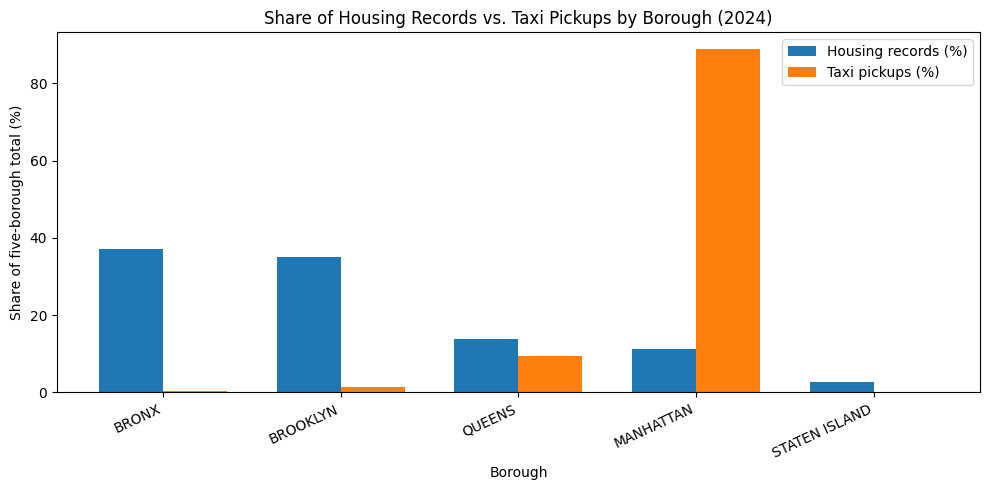

,borough,housing_record_share,taxi_pickup_share
0,BRONX,37.17,0.31
1,BROOKLYN,34.98,1.46
3,QUEENS,13.92,9.48
2,MANHATTAN,11.28,88.75
4,STATEN ISLAND,2.65,0.00


In [41]:
# Q1: Compare borough shares of housing records and taxi pickups
share_data = integrated[["borough", "housing_records", "total_pickups"]].copy()
share_data["housing_record_share"] = share_data["housing_records"] / share_data["housing_records"].sum() * 100
share_data["taxi_pickup_share"] = share_data["total_pickups"] / share_data["total_pickups"].sum() * 100
share_data = share_data.sort_values("housing_record_share", ascending=False)
x = np.arange(len(share_data))
width = 0.36
plt.figure(figsize=(10, 5))
plt.bar(x - width/2, share_data["housing_record_share"], width, label="Housing records (%)")
plt.bar(x + width/2, share_data["taxi_pickup_share"], width, label="Taxi pickups (%)")
plt.title("Share of Housing Records vs. Taxi Pickups by Borough (2024)")
plt.xlabel("Borough")
plt.ylabel("Share of five-borough total (%)")
plt.xticks(x, share_data["borough"], rotation=25, ha="right")
plt.legend()
plt.tight_layout()
plt.show()
display(share_data[["borough", "housing_record_share", "taxi_pickup_share"]].round(2))


### Research Question 2: Across the five boroughs, is a higher number of affordable-housing records associated with more yellow taxi pickups?

**Visualization:** Scatter plot comparing 2024 housing-record counts with recorded yellow taxi pickups by borough.

**Finding:** The borough comparison shows that the measures do not move together in a simple way: the Bronx has the most selected housing records, while Manhattan has by far the most taxi pickups. The borough-level pattern therefore does not support assuming that more housing records automatically correspond to more taxi activity.

**Limitation:** There are only five borough-level observations. Housing records are not necessarily unique buildings or new units, and taxi pickups are not a measure of all transportation.


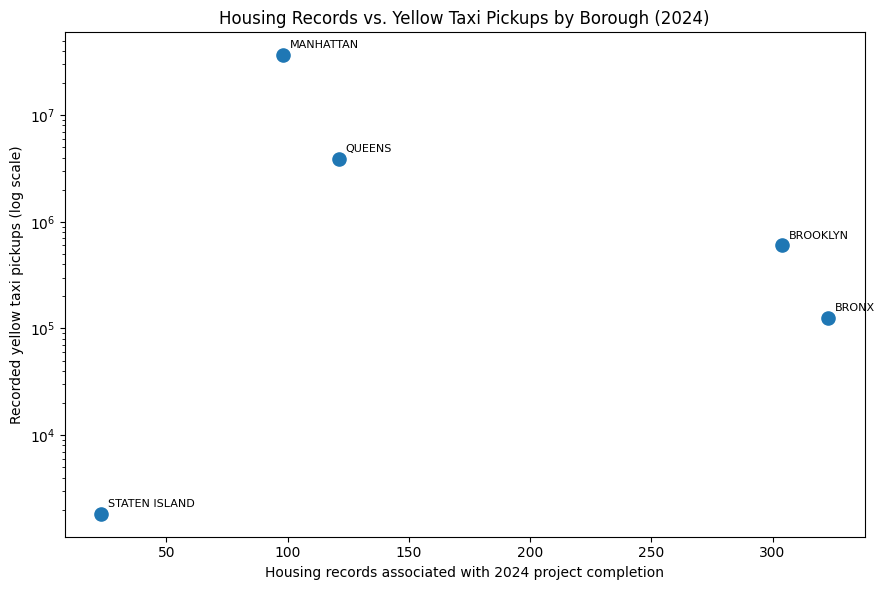

In [42]:
# Q2: Housing-record counts versus taxi pickups by borough
plot_data = integrated.dropna(subset=["housing_records", "total_pickups"]).copy()
plt.figure(figsize=(9, 6))
plt.scatter(plot_data["housing_records"], plot_data["total_pickups"], s=90)
for _, row in plot_data.iterrows():
    plt.annotate(row["borough"], (row["housing_records"], row["total_pickups"]),
                 xytext=(5, 5), textcoords="offset points", fontsize=8)
plt.yscale("log")
plt.title("Housing Records vs. Yellow Taxi Pickups by Borough (2024)")
plt.xlabel("Housing records associated with 2024 project completion")
plt.ylabel("Recorded yellow taxi pickups (log scale)")
plt.tight_layout()
plt.show()


### Research Question 3: How do recorded housing-unit totals compare with yellow taxi pickup activity across NYC boroughs?

**Visualization:** Scatter plot comparing the sum of recorded housing units with 2024 yellow taxi pickups by borough, using logarithmic axes.

**Finding:** The Bronx has the largest recorded housing-unit total, while Manhattan has the largest taxi pickup total. Queens also records substantially more taxi pickups than Brooklyn despite Brooklyn's higher recorded housing-unit total. The borough ranking differs between the two measures.

**Limitation:** The housing-unit values are sums of the source field for records associated with projects completed in 2024; they should not automatically be interpreted as newly created or occupied units. The comparison contains five boroughs and cannot establish causation.


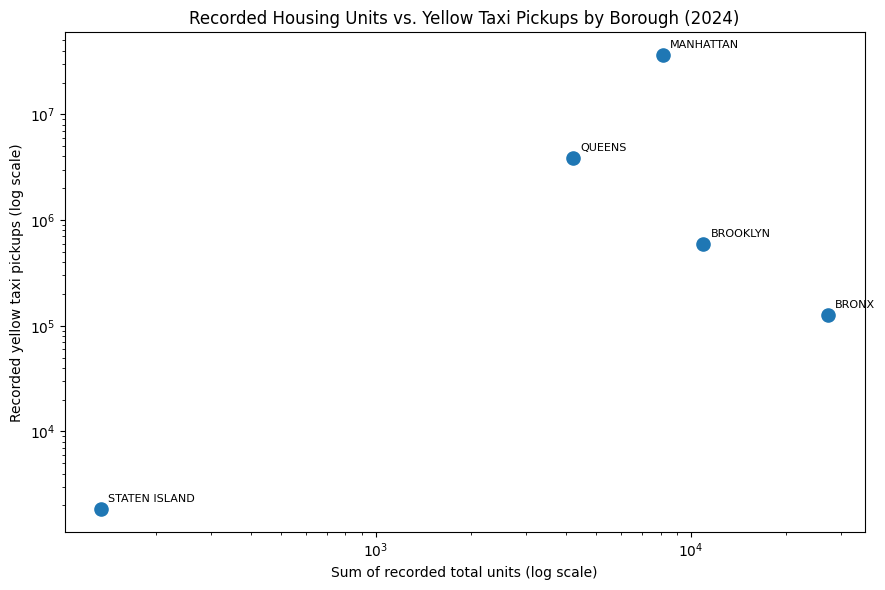

In [43]:
# Q3: Recorded housing-unit totals versus taxi pickups by borough
plot_data = integrated.dropna(subset=["total_units_sum", "total_pickups"]).copy()
plt.figure(figsize=(9, 6))
plt.scatter(plot_data["total_units_sum"], plot_data["total_pickups"], s=90)
for _, row in plot_data.iterrows():
    plt.annotate(row["borough"], (row["total_units_sum"], row["total_pickups"]),
                 xytext=(5, 5), textcoords="offset points", fontsize=8)
plt.xscale("log")
plt.yscale("log")
plt.title("Recorded Housing Units vs. Yellow Taxi Pickups by Borough (2024)")
plt.xlabel("Sum of recorded total units (log scale)")
plt.ylabel("Recorded yellow taxi pickups (log scale)")
plt.tight_layout()
plt.show()


### Research Question 4: Does the number of unique affordable-housing projects by borough align with recorded yellow taxi pickup activity?

**Visualization:** Scatter plot comparing unique housing projects completed in 2024 with recorded taxi pickups by borough.

**Finding:** The comparison separates the number of distinct project IDs from the number of housing records. Manhattan still has the highest taxi pickup total, while the selected housing-project counts are distributed differently across boroughs.

**Limitation:** A project count does not indicate project size, occupancy, or transit demand. With only five boroughs, this is descriptive rather than conclusive evidence.


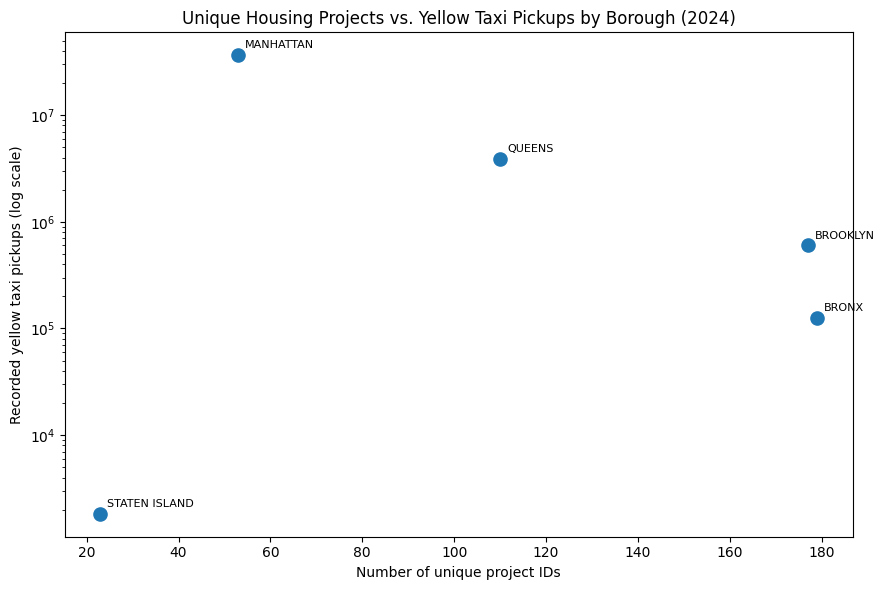

In [44]:
# Q4: Unique housing projects versus taxi pickups by borough
plot_data = integrated.dropna(subset=["unique_projects", "total_pickups"]).copy()
plt.figure(figsize=(9, 6))
plt.scatter(plot_data["unique_projects"], plot_data["total_pickups"], s=90)
for _, row in plot_data.iterrows():
    plt.annotate(row["borough"], (row["unique_projects"], row["total_pickups"]),
                 xytext=(5, 5), textcoords="offset points", fontsize=8)
plt.yscale("log")
plt.title("Unique Housing Projects vs. Yellow Taxi Pickups by Borough (2024)")
plt.xlabel("Number of unique project IDs")
plt.ylabel("Recorded yellow taxi pickups (log scale)")
plt.tight_layout()
plt.show()


### Research Question 5: Do monthly changes in housing project completions follow the same pattern as monthly yellow taxi pickups in 2024?

**Visualization:** Line chart comparing each month's share of annual housing records associated with 2024 project completion dates with that month's share of annual taxi pickups.

**Finding:** Taxi pickups were highest in October and lowest in January. Housing project-completion records peaked in June and were lowest in February. The different peak months indicate that the two monthly distributions do not follow the same pattern throughout the year.

**Limitation:** Project completion dates are not the same as individual building completion dates or move-in dates. Monthly alignment does not show that one measure causes changes in the other.


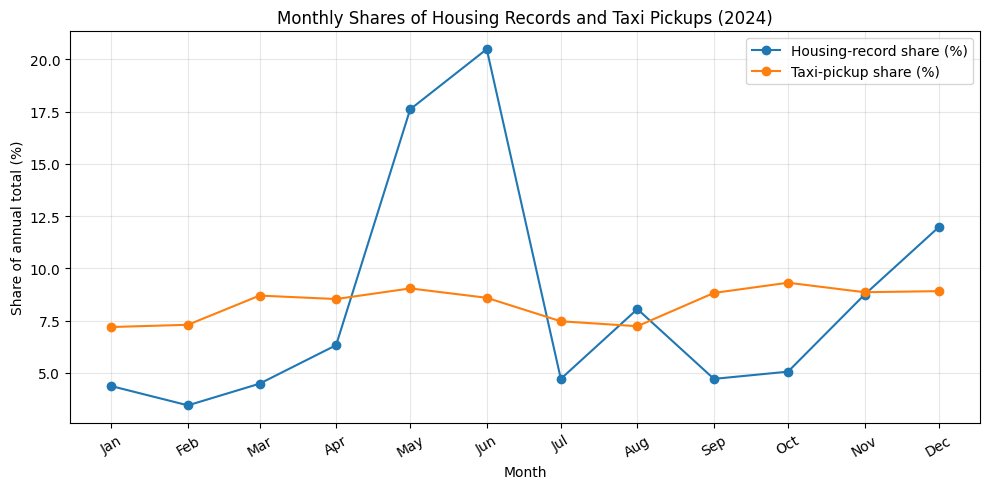

,month,housing_records,taxi_pickups,housing_share,taxi_share
0,2024-01-01,38,2952303,4.372842,7.197663
1,2024-02-01,30,2996153,3.452244,7.304568
2,2024-03-01,39,3568591,4.487917,8.700162
3,2024-04-01,55,3500938,6.329114,8.535225
4,2024-05-01,153,3709385,17.606444,9.043415
5,2024-06-01,178,3525174,20.483314,8.594312
6,2024-07-01,41,3064593,4.718067,7.471424
7,2024-08-01,70,2968218,8.055236,7.236463
8,2024-09-01,41,3620769,4.718067,8.827371
9,2024-10-01,44,3820772,5.063291,9.314975


In [45]:
# Q5: Compare monthly shares of housing project records and taxi pickups
housing_project_monthly = (
    housing_2024.assign(month=housing_2024["project_completion_date"].dt.to_period("M").dt.to_timestamp())
    .groupby("month", as_index=False)
    .size()
    .rename(columns={"size": "housing_records"})
)
taxi_monthly = taxi_clean.groupby("pickup_month", as_index=False)["pickup_trips"].sum().sort_values("pickup_month")
monthly_share_compare = housing_project_monthly.merge(
    taxi_monthly.rename(columns={"pickup_month": "month", "pickup_trips": "taxi_pickups"}),
    on="month", how="outer"
).sort_values("month")
monthly_share_compare["housing_share"] = monthly_share_compare["housing_records"] / monthly_share_compare["housing_records"].sum() * 100
monthly_share_compare["taxi_share"] = monthly_share_compare["taxi_pickups"] / monthly_share_compare["taxi_pickups"].sum() * 100
plt.figure(figsize=(10, 5))
plt.plot(monthly_share_compare["month"], monthly_share_compare["housing_share"], marker="o", label="Housing-record share (%)")
plt.plot(monthly_share_compare["month"], monthly_share_compare["taxi_share"], marker="o", label="Taxi-pickup share (%)")
plt.title("Monthly Shares of Housing Records and Taxi Pickups (2024)")
plt.xlabel("Month")
plt.ylabel("Share of annual total (%)")
plt.xticks(monthly_share_compare["month"], [d.strftime("%b") for d in monthly_share_compare["month"]], rotation=30)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
display(monthly_share_compare)


In [46]:
# Find the months with the highest and lowest pickup totals

taxi_monthly["pickup_month"] = pd.to_datetime(
    taxi_monthly["pickup_month"]
)

highest_month = taxi_monthly.loc[
    taxi_monthly["pickup_trips"].idxmax()
]

lowest_month = taxi_monthly.loc[
    taxi_monthly["pickup_trips"].idxmin()
]

print(
    "Highest pickup month:",
    highest_month["pickup_month"].strftime("%B %Y"),
    "-",
    f'{highest_month["pickup_trips"]:,}',
    "pickups"
)

print(
    "Lowest pickup month:",
    lowest_month["pickup_month"].strftime("%B %Y"),
    "-",
    f'{lowest_month["pickup_trips"]:,}',
    "pickups"
)

print("\nMonthly pickup totals:")
display(taxi_monthly)

Highest pickup month: October 2024 - 3,820,772 pickups
Lowest pickup month: January 2024 - 2,952,303 pickups

Monthly pickup totals:


,pickup_month,pickup_trips
0,2024-01-01,2952303
1,2024-02-01,2996153
2,2024-03-01,3568591
3,2024-04-01,3500938
4,2024-05-01,3709385
5,2024-06-01,3525174
6,2024-07-01,3064593
7,2024-08-01,2968218
8,2024-09-01,3620769
9,2024-10-01,3820772


### Research Question 6: Within each borough, do monthly housing project-completion patterns move alongside monthly taxi pickup patterns?

**Visualization:** Small-multiple line charts by borough comparing monthly housing project-completion records and monthly taxi pickups after scaling each measure to its own annual borough total.

**Finding:** In both the Bronx and Brooklyn, taxi pickups were highest in November and lowest in January. Comparing monthly taxi pickup shares with monthly housing project-completion records helps show whether housing completion patterns follow similar seasonal trends within each borough. The housing pattern must be checked against the chart before concluding whether the two measures move together.

**Limitation:** Housing records are counted by project completion date, while taxi data counts recorded pickups. These measures represent different activities, so similar monthly patterns do not prove that housing completions caused changes in taxi activity. The comparison covers only 12 months in 2024.


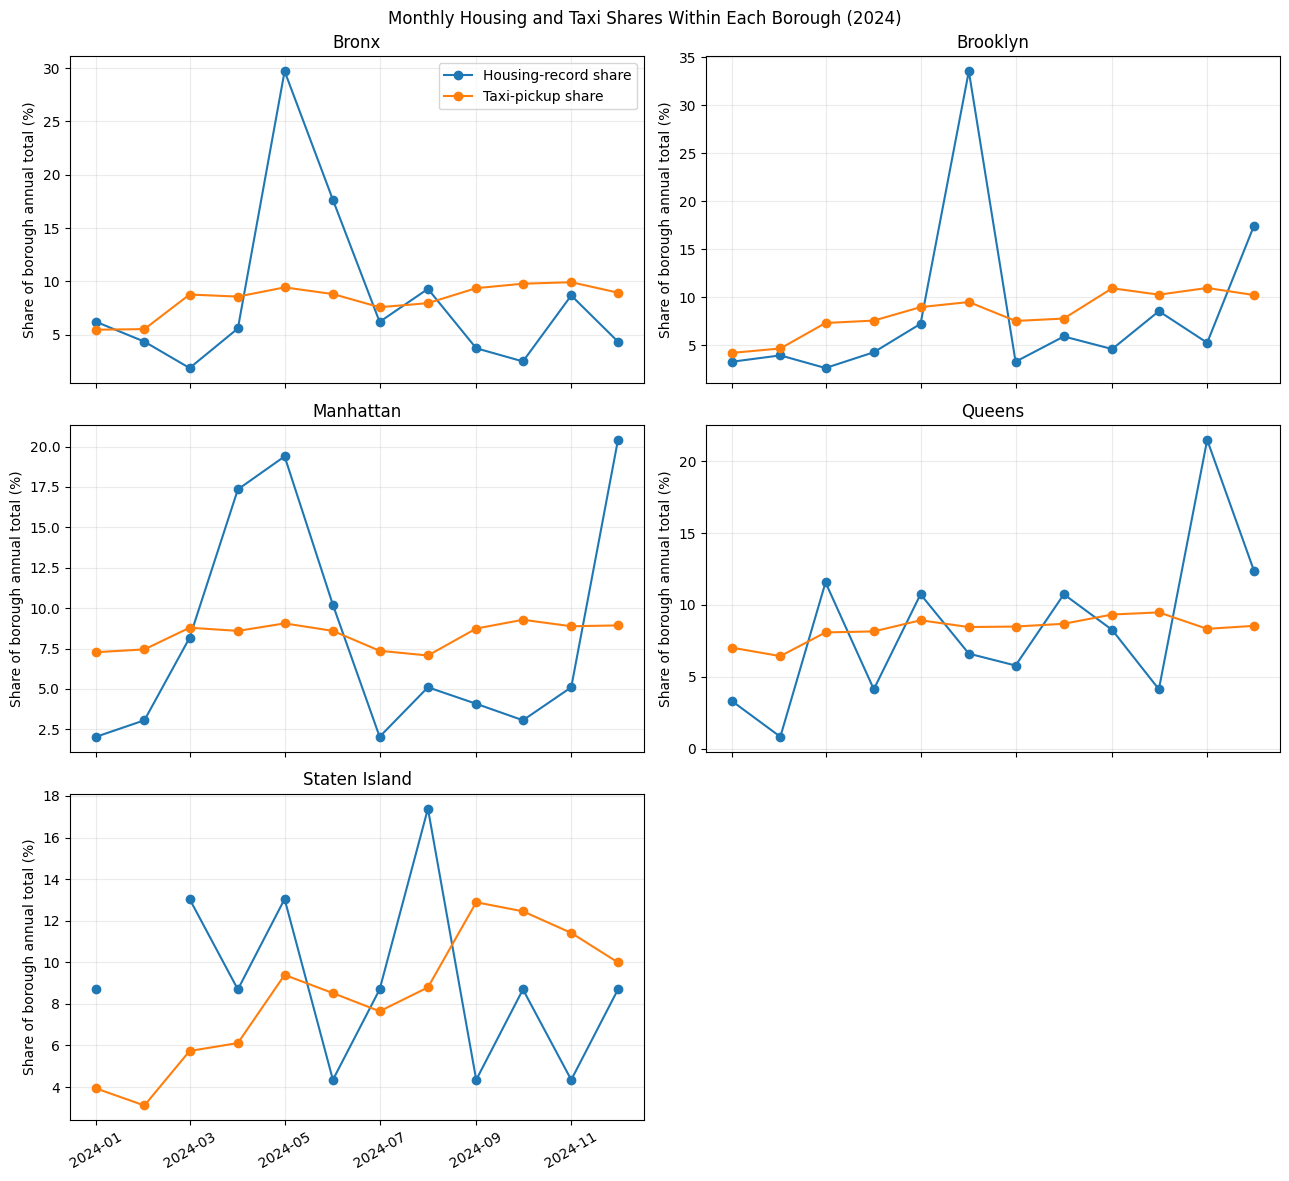

In [47]:

# Q6: Compare monthly housing and taxi patterns within each borough

# Prepare monthly housing records
housing_borough_project_monthly = (
    housing_2024.assign(
        borough=housing_2024["borough"].str.strip().str.upper(),
        month=housing_2024["project_completion_date"]
            .dt.to_period("M").dt.to_timestamp()
    )
    .groupby(["borough", "month"], as_index=False)
    .size()
    .rename(columns={"size": "housing_records"})
)

# Create monthly taxi pickups by borough from taxi_clean
taxi_monthly_borough = (
    taxi_clean.groupby(
        ["taxi_borough", "pickup_month"], as_index=False
    )["pickup_trips"]
    .sum()
)

taxi_monthly_borough["taxi_borough"] = (
    taxi_monthly_borough["taxi_borough"].str.strip().str.upper()
)
taxi_monthly_borough["pickup_month"] = pd.to_datetime(
    taxi_monthly_borough["pickup_month"]
)

# Plot each borough separately
fig, axes = plt.subplots(3, 2, figsize=(13, 12), sharex=True)
axes = axes.flatten()

borough_list = sorted(
    set(housing_borough_project_monthly["borough"].dropna())
    & set(taxi_monthly_borough["taxi_borough"].dropna())
)

for ax, borough in zip(axes, borough_list):
    h = housing_borough_project_monthly[
        housing_borough_project_monthly["borough"] == borough
    ][["month", "housing_records"]]

    t = taxi_monthly_borough[
        taxi_monthly_borough["taxi_borough"] == borough
    ][["pickup_month", "pickup_trips"]].rename(
        columns={"pickup_month": "month"}
    )

    both = h.merge(t, on="month", how="outer").sort_values("month")

    both["housing_share"] = (
        both["housing_records"] / both["housing_records"].sum() * 100
    )
    both["taxi_share"] = (
        both["pickup_trips"] / both["pickup_trips"].sum() * 100
    )

    ax.plot(
        both["month"], both["housing_share"],
        marker="o", label="Housing-record share"
    )
    ax.plot(
        both["month"], both["taxi_share"],
        marker="o", label="Taxi-pickup share"
    )
    ax.set_title(borough.title())
    ax.set_ylabel("Share of borough annual total (%)")
    ax.grid(True, alpha=0.25)
    ax.tick_params(axis="x", rotation=30)

for ax in axes[len(borough_list):]:
    ax.set_visible(False)

axes[0].legend()
fig.suptitle("Monthly Housing and Taxi Shares Within Each Borough (2024)")
fig.tight_layout()
plt.show()



In [48]:
# Question 6: Summarize monthly pickup patterns by borough

taxi_monthly_borough["pickup_month"] = pd.to_datetime(
    taxi_monthly_borough["pickup_month"]
)

for borough in sorted(taxi_monthly_borough["taxi_borough"].unique()):
    data = taxi_monthly_borough[
        taxi_monthly_borough["taxi_borough"] == borough
    ]

    highest = data.loc[data["pickup_trips"].idxmax()]
    lowest = data.loc[data["pickup_trips"].idxmin()]

    print(f"\n{borough}")
    print(
        "Highest:",
        highest["pickup_month"].strftime("%B"),
        f'{highest["pickup_trips"]:,}',
        "pickups"
    )
    print(
        "Lowest:",
        lowest["pickup_month"].strftime("%B"),
        f'{lowest["pickup_trips"]:,}',
        "pickups"
    )


BRONX
Highest: November 12,544 pickups
Lowest: January 6,905 pickups

BROOKLYN
Highest: November 65,826 pickups
Lowest: January 25,258 pickups

MANHATTAN
Highest: October 3,377,946 pickups
Lowest: August 2,573,483 pickups

QUEENS
Highest: October 368,586 pickups
Lowest: February 250,312 pickups

STATEN ISLAND
Highest: September 236 pickups
Lowest: February 57 pickups


### Research Question 7: How does zone-level taxi pickup intensity by borough compare with the distribution of affordable-housing records across those boroughs?

**Visualization:** Two-panel chart comparing median monthly pickups per taxi zone by borough with each borough's share of 2024 housing records.

**Finding:** Manhattan has the highest median zone-month pickup count, while the Bronx and Brooklyn have the largest shares of the selected housing records. The comparison highlights that housing-record concentration and taxi pickup intensity are not distributed in the same way.

**Limitation:** Zone-month pickup counts are not individual trip counts per resident, and the housing data is summarized at building/project-record level. The measures have different denominators and should not be interpreted as a direct accessibility score.


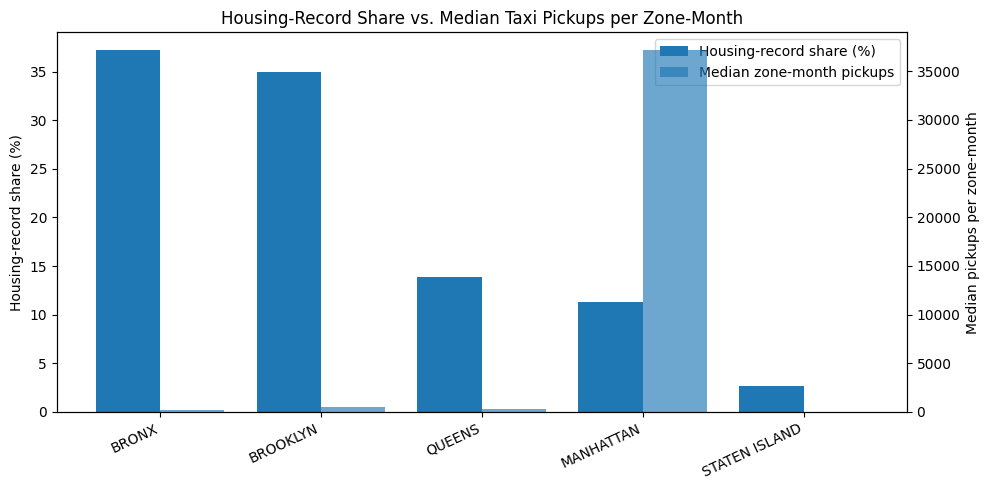

,median_zone_month_pickups,housing_record_share
BRONX,208.5,37.17
BROOKLYN,521.0,34.98
QUEENS,279.0,13.92
MANHATTAN,37127.0,11.28
STATEN ISLAND,5.0,2.65


In [49]:
# Q7: Compare taxi zone-month pickup intensity with housing-record share by borough
taxi_zone_median = taxi_clean.groupby("taxi_borough")["pickup_trips"].median().rename("median_zone_month_pickups")
housing_share_by_borough = share_data.set_index("borough")["housing_record_share"]
comparison = taxi_zone_median.to_frame().join(housing_share_by_borough, how="inner")
comparison = comparison.sort_values("housing_record_share", ascending=False)
fig, ax1 = plt.subplots(figsize=(10, 5))
x = np.arange(len(comparison))
ax1.bar(x - 0.2, comparison["housing_record_share"], width=0.4, label="Housing-record share (%)")
ax1.set_ylabel("Housing-record share (%)")
ax1.set_xticks(x)
ax1.set_xticklabels(comparison.index, rotation=25, ha="right")
ax2 = ax1.twinx()
ax2.bar(x + 0.2, comparison["median_zone_month_pickups"], width=0.4, alpha=0.65, label="Median zone-month pickups")
ax2.set_ylabel("Median pickups per zone-month")
ax1.set_title("Housing-Record Share vs. Median Taxi Pickups per Zone-Month")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1+h2, l1+l2, loc="upper right")
fig.tight_layout()
plt.show()
display(comparison.round(2))


In [50]:
# Q7: Summarize pickup distributions by borough

summary = (
    taxi_clean.groupby("taxi_borough")["pickup_trips"]
    .agg(
        zone_month_records="count",
        median="median",
        minimum="min",
        maximum="max",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75)
    )
)

summary["IQR"] = summary["Q3"] - summary["Q1"]

display(summary.round(2))

,zone_month_records,median,minimum,maximum,Q1,Q3,IQR
taxi_borough,,,,,,,
BRONX,514,208.5,1,1331,130.25,305.75,175.50
BROOKLYN,732,521.0,1,4008,243.75,1152.50,908.75
MANHATTAN,796,37127.0,1,191012,6932.50,72508.25,65575.75
QUEENS,828,279.0,2,194114,107.75,760.25,652.50
STATEN ISLAND,198,5.0,1,70,2.00,11.00,9.00


### Research Question 8: Do boroughs and months with more housing completion records also show higher taxi pickup activity?

**Visualization:** Side-by-side heatmaps showing monthly housing project-completion records and monthly taxi pickups for each borough.

**Finding:** The heatmaps allow the timing and borough distribution of the two datasets to be compared directly. Taxi activity is consistently much higher in Manhattan, while the largest housing-record counts are concentrated in the Bronx and Brooklyn; monthly peaks also differ.

**Limitation:** The color scales represent different units, so colors should be compared within each heatmap rather than directly between panels. Missing borough-month housing records should not automatically be interpreted as zero completed projects.


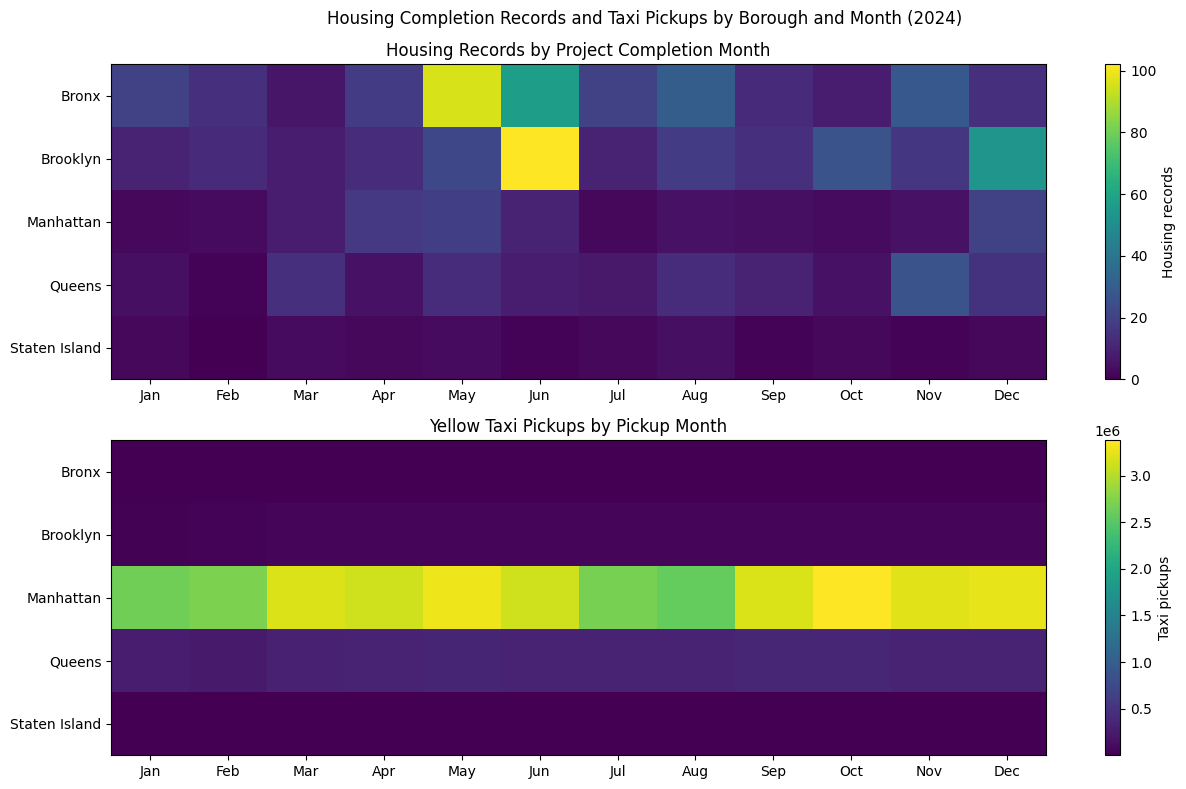

In [51]:
# Q8: Side-by-side heatmaps of monthly housing records and taxi pickups by borough
housing_heat = (
    housing_2024.assign(
        borough=housing_2024["borough"].str.strip().str.upper(),
        month=housing_2024["project_completion_date"].dt.to_period("M").dt.to_timestamp()
    )
    .groupby(["borough", "month"]).size().unstack(fill_value=0)
)
taxi_heat = taxi_monthly_borough.pivot(index="taxi_borough", columns="pickup_month", values="pickup_trips").fillna(0)
taxi_heat.index = taxi_heat.index.str.strip().str.upper()
months = pd.date_range("2024-01-01", "2024-12-01", freq="MS")
borough_order = ["BRONX", "BROOKLYN", "MANHATTAN", "QUEENS", "STATEN ISLAND"]
housing_heat = housing_heat.reindex(index=borough_order, columns=months, fill_value=0)
taxi_heat = taxi_heat.reindex(index=borough_order, columns=months, fill_value=0)
fig, axes = plt.subplots(2, 1, figsize=(13, 8))
im1 = axes[0].imshow(housing_heat.values, aspect="auto")
axes[0].set_title("Housing Records by Project Completion Month")
axes[0].set_yticks(range(len(borough_order))); axes[0].set_yticklabels([b.title() for b in borough_order])
axes[0].set_xticks(range(12)); axes[0].set_xticklabels([m.strftime("%b") for m in months])
fig.colorbar(im1, ax=axes[0], label="Housing records")
im2 = axes[1].imshow(taxi_heat.values, aspect="auto")
axes[1].set_title("Yellow Taxi Pickups by Pickup Month")
axes[1].set_yticks(range(len(borough_order))); axes[1].set_yticklabels([b.title() for b in borough_order])
axes[1].set_xticks(range(12)); axes[1].set_xticklabels([m.strftime("%b") for m in months])
fig.colorbar(im2, ax=axes[1], label="Taxi pickups")
fig.suptitle("Housing Completion Records and Taxi Pickups by Borough and Month (2024)")
fig.tight_layout()
plt.show()


In [52]:
# Q8: Identify the highest and lowest borough-month pickup totals

highest = taxi_monthly_borough.loc[
    taxi_monthly_borough["pickup_trips"].idxmax()
]

lowest = taxi_monthly_borough.loc[
    taxi_monthly_borough["pickup_trips"].idxmin()
]

print(
    "Highest activity:",
    highest["taxi_borough"],
    "-",
    highest["pickup_month"].strftime("%B %Y"),
    "-",
    f'{highest["pickup_trips"]:,}',
    "pickups"
)

print(
    "Lowest activity:",
    lowest["taxi_borough"],
    "-",
    lowest["pickup_month"].strftime("%B %Y"),
    "-",
    f'{lowest["pickup_trips"]:,}',
    "pickups"
)

Highest activity: MANHATTAN - October 2024 - 3,377,946 pickups
Lowest activity: STATEN ISLAND - February 2024 - 57 pickups


### Research Question 9: Across the 12 months of 2024, is the number of records associated with completed housing projects related to total yellow taxi pickups?

**Visualization:** Scatter plot comparing monthly housing project-completion record counts with monthly taxi pickup totals.

**Finding:** Housing records associated with project completion dates peaked in June (178 records) and were lowest in February (30 records). Taxi pickups peaked in October (3,820,772 pickups) and were lowest in January (2,952,303 pickups). These different peak and low months suggest that the two monthly distributions do not follow the same pattern throughout the year.

**Limitation:** The comparison has only 12 monthly observations. A housing record is not equivalent to a completed or occupied home, and correlation does not establish causation.

In [53]:

# Q9: Identify months with the highest and lowest housing record counts

# Create monthly housing summary using 2024 project completion dates
housing_monthly = (
    housing_2024
    .assign(
        completion_month=housing_2024["project_completion_date"]
        .dt.to_period("M").dt.to_timestamp()
    )
    .groupby("completion_month")
    .agg(
        housing_records=("project_id", "size"),
        unique_projects=("project_id", "nunique")
    )
    .reset_index()
    .sort_values("completion_month")
)

# Find the highest and lowest months
highest = housing_monthly.loc[
    housing_monthly["housing_records"].idxmax()
]

lowest = housing_monthly.loc[
    housing_monthly["housing_records"].idxmin()
]

print(
    "Highest month:",
    highest["completion_month"].strftime("%B"),
    "-",
    int(highest["housing_records"]),
    "housing records,",
    int(highest["unique_projects"]),
    "unique projects"
)

print(
    "Lowest month:",
    lowest["completion_month"].strftime("%B"),
    "-",
    int(lowest["housing_records"]),
    "housing records,",
    int(lowest["unique_projects"]),
    "unique projects"
)

print("\nMonthly housing records:")
display(housing_monthly)



Highest month: June - 178 housing records, 59 unique projects
Lowest month: February - 30 housing records, 26 unique projects

Monthly housing records:


,completion_month,housing_records,unique_projects
0,2024-01-01,38,27
1,2024-02-01,30,26
2,2024-03-01,39,37
3,2024-04-01,55,37
4,2024-05-01,153,61
5,2024-06-01,178,59
6,2024-07-01,41,36
7,2024-08-01,70,68
8,2024-09-01,41,37
9,2024-10-01,44,35


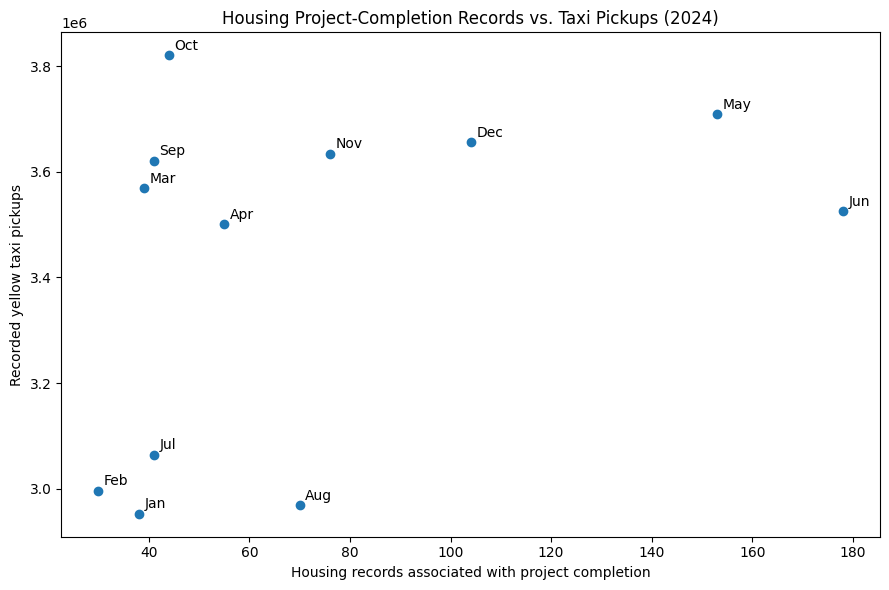

,month,housing_records,taxi_pickups
0,2024-01-01,38,2952303
1,2024-02-01,30,2996153
2,2024-03-01,39,3568591
3,2024-04-01,55,3500938
4,2024-05-01,153,3709385
5,2024-06-01,178,3525174
6,2024-07-01,41,3064593
7,2024-08-01,70,2968218
8,2024-09-01,41,3620769
9,2024-10-01,44,3820772


In [54]:

# Q9: Monthly project-completion records versus taxi pickups

# Prepare monthly housing project-completion records
housing_project_monthly = (
    housing_2024
    .assign(
        month=housing_2024["project_completion_date"]
        .dt.to_period("M").dt.to_timestamp()
    )
    .groupby("month", as_index=False)
    .size()
    .rename(columns={"size": "housing_records"})
)

# Prepare monthly taxi pickup totals
taxi_monthly_for_project = (
    taxi_clean
    .groupby("pickup_month", as_index=False)["pickup_trips"]
    .sum()
    .rename(columns={
        "pickup_month": "month",
        "pickup_trips": "taxi_pickups"
    })
)

taxi_monthly_for_project["month"] = pd.to_datetime(
    taxi_monthly_for_project["month"]
)

# Combine the two datasets by month
project_month_comparison = housing_project_monthly.merge(
    taxi_monthly_for_project,
    on="month",
    how="inner"
).sort_values("month")

# Draw the scatter plot
plt.figure(figsize=(9, 6))

plt.scatter(
    project_month_comparison["housing_records"],
    project_month_comparison["taxi_pickups"]
)

for _, row in project_month_comparison.iterrows():
    plt.annotate(
        row["month"].strftime("%b"),
        (row["housing_records"], row["taxi_pickups"]),
        xytext=(4, 4),
        textcoords="offset points"
    )

plt.title("Housing Project-Completion Records vs. Taxi Pickups (2024)")
plt.xlabel("Housing records associated with project completion")
plt.ylabel("Recorded yellow taxi pickups")
plt.tight_layout()
plt.show()

# Display the data used in the chart
display(project_month_comparison)


### Research Question 10: Are months with more individual building-completion records associated with more yellow taxi pickups?

**Visualization:** Scatter plot comparing monthly housing records with a building completion date in 2024 against monthly taxi pickups.

**Finding:** The 12 monthly observations produced a Pearson correlation of approximately 0.417, indicating a moderate positive association. However, the pattern is not consistent in every month, and October's taxi pickup peak does not coincide with the peak in building-completion records.

**Limitation:** Only 12 months are compared. Building completion dates differ from project completion dates, and other factors may affect taxi activity. The association does not demonstrate causation.


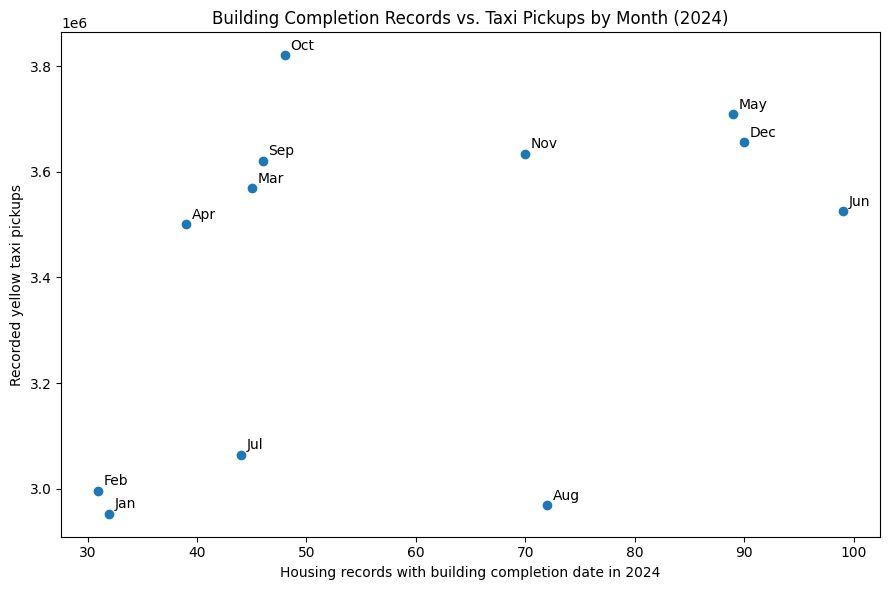

,month,building_completion_records,taxi_pickups
0,2024-01-01,32,2952303
1,2024-02-01,31,2996153
2,2024-03-01,45,3568591
3,2024-04-01,39,3500938
4,2024-05-01,89,3709385
5,2024-06-01,99,3525174
6,2024-07-01,44,3064593
7,2024-08-01,72,2968218
8,2024-09-01,46,3620769
9,2024-10-01,48,3820772


In [55]:
# Q10: Building completion records versus monthly taxi pickups
housing_building_monthly = (
    housing_clean.loc[housing_clean["building_completion_date"].dt.year == 2024]
    .assign(month=lambda df: df["building_completion_date"].dt.to_period("M").dt.to_timestamp())
    .groupby("month", as_index=False).size()
    .rename(columns={"size": "building_completion_records"})
)
taxi_monthly_for_compare = taxi_monthly.rename(columns={"pickup_month": "month", "pickup_trips": "taxi_pickups"})
monthly_comparison = housing_building_monthly.merge(taxi_monthly_for_compare, on="month", how="inner").sort_values("month")
plt.figure(figsize=(9, 6))
plt.scatter(monthly_comparison["building_completion_records"], monthly_comparison["taxi_pickups"])
for _, row in monthly_comparison.iterrows():
    plt.annotate(row["month"].strftime("%b"), (row["building_completion_records"], row["taxi_pickups"]),
                 xytext=(4, 4), textcoords="offset points")
plt.title("Building Completion Records vs. Taxi Pickups by Month (2024)")
plt.xlabel("Housing records with building completion date in 2024")
plt.ylabel("Recorded yellow taxi pickups")
plt.tight_layout()
plt.show()
display(monthly_comparison)


In [56]:
# Q10: Measure the monthly relationship between housing records and taxi pickups

print("Monthly comparison:")
display(monthly_comparison)

print("\nCorrelation between the two monthly measures:")

correlation = monthly_comparison[
    ["building_completion_records", "taxi_pickups"]
].corr().iloc[0, 1]

print("Pearson correlation:", round(correlation, 3))

print(
    "Months included:",
    len(monthly_comparison)
)

Monthly comparison:


,month,building_completion_records,taxi_pickups
0,2024-01-01,32,2952303
1,2024-02-01,31,2996153
2,2024-03-01,45,3568591
3,2024-04-01,39,3500938
4,2024-05-01,89,3709385
5,2024-06-01,99,3525174
6,2024-07-01,44,3064593
7,2024-08-01,72,2968218
8,2024-09-01,46,3620769
9,2024-10-01,48,3820772



Correlation between the two monthly measures:
Pearson correlation: 0.417
Months included: 12


### Research Question 11: Does the association between monthly building-completion records and taxi pickups differ by borough?

**Visualization:** Scatter plot of borough-month observations, with a separate color for each borough.

**Finding:** The relationship differs across boroughs: Brooklyn shows a strong positive correlation (0.813), followed by Manhattan (0.539) and Queens (0.399). The Bronx shows a weak positive correlation (0.164), while Staten Island shows a negative correlation (-0.333).

**Limitation:** The analysis has 59 borough-month observations: 12 per borough except Staten Island, which has 11. The estimates are sensitive to the small sample size and do not establish causation.


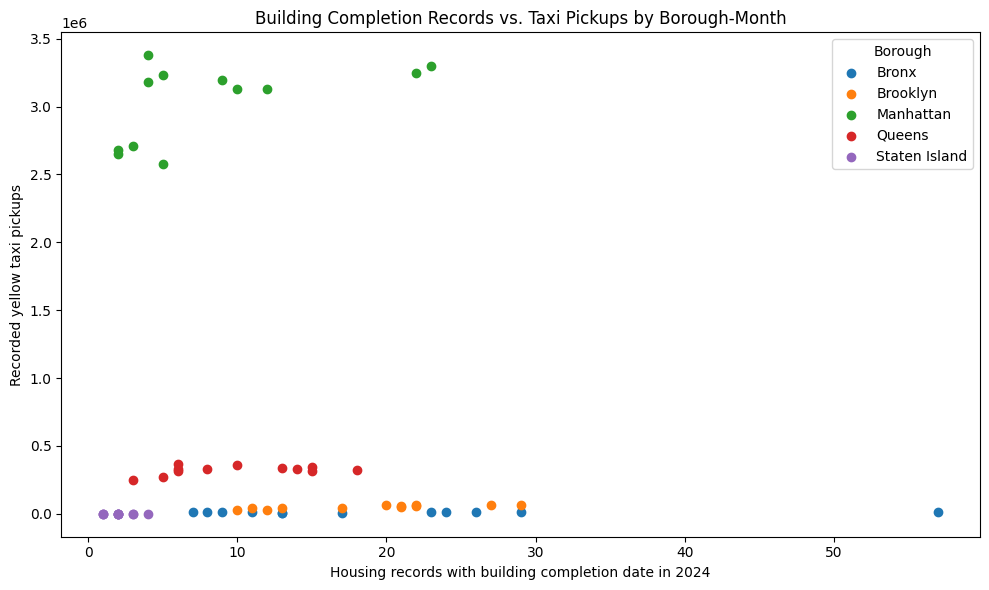

Total borough-month observations: 59


,borough,month,housing_records,taxi_pickups
0,BRONX,2024-01-01,13,6905
1,BRONX,2024-02-01,13,6972
2,BRONX,2024-03-01,7,11082
3,BRONX,2024-04-01,8,10836
4,BRONX,2024-05-01,26,11930
5,BRONX,2024-06-01,57,11140
6,BRONX,2024-07-01,17,9574
7,BRONX,2024-08-01,29,10060
8,BRONX,2024-09-01,11,11841
9,BRONX,2024-10-01,9,12367


In [57]:
# Q11: Building completion records versus taxi pickups by borough-month
housing_borough_monthly = (
    housing_clean.loc[housing_clean["building_completion_date"].dt.year == 2024]
    .assign(
        borough=lambda df: df["borough"].str.strip().str.upper(),
        month=lambda df: df["building_completion_date"].dt.to_period("M").dt.to_timestamp()
    )
    .groupby(["borough", "month"], as_index=False).size()
    .rename(columns={"size": "housing_records"})
)
taxi_borough_monthly_for_compare = taxi_monthly_borough.rename(
    columns={"taxi_borough": "borough", "pickup_month": "month", "pickup_trips": "taxi_pickups"}
).copy()
taxi_borough_monthly_for_compare["borough"] = taxi_borough_monthly_for_compare["borough"].str.strip().str.upper()
taxi_borough_monthly_for_compare["month"] = pd.to_datetime(taxi_borough_monthly_for_compare["month"])
borough_month_comparison = housing_borough_monthly.merge(
    taxi_borough_monthly_for_compare, on=["borough", "month"], how="inner", validate="one_to_one"
)
plt.figure(figsize=(10, 6))
for borough, group in borough_month_comparison.groupby("borough"):
    plt.scatter(group["housing_records"], group["taxi_pickups"], label=borough.title())
plt.title("Building Completion Records vs. Taxi Pickups by Borough-Month")
plt.xlabel("Housing records with building completion date in 2024")
plt.ylabel("Recorded yellow taxi pickups")
plt.legend(title="Borough")
plt.tight_layout()
plt.show()
print("Total borough-month observations:", len(borough_month_comparison))
display(borough_month_comparison.head(10))


In [58]:
print("Housing monthly data:")
print(housing_borough_monthly.head())
print(housing_borough_monthly["month"].min())
print(housing_borough_monthly["month"].max())

print("\nTaxi monthly data:")
print(taxi_monthly_borough.head())
print(taxi_monthly_borough["pickup_month"].min())
print(taxi_monthly_borough["pickup_month"].max())

print("\nHousing boroughs:")
print(housing_borough_monthly["borough"].unique())

print("\nTaxi boroughs:")
print(taxi_monthly_borough["taxi_borough"].unique())

Housing monthly data:
  borough      month  housing_records
0   BRONX 2024-01-01               13
1   BRONX 2024-02-01               13
2   BRONX 2024-03-01                7
3   BRONX 2024-04-01                8
4   BRONX 2024-05-01               26
2024-01-01 00:00:00
2024-12-01 00:00:00

Taxi monthly data:
  taxi_borough pickup_month  pickup_trips
0        BRONX   2024-01-01          6905
1        BRONX   2024-02-01          6972
2        BRONX   2024-03-01         11082
3        BRONX   2024-04-01         10836
4        BRONX   2024-05-01         11930
2024-01-01 00:00:00
2024-12-01 00:00:00

Housing boroughs:
<StringArray>
['BRONX', 'BROOKLYN', 'MANHATTAN', 'QUEENS', 'STATEN ISLAND']
Length: 5, dtype: string

Taxi boroughs:
['BRONX' 'BROOKLYN' 'MANHATTAN' 'QUEENS' 'STATEN ISLAND']


### Research Question 12: Which boroughs have a larger share of housing records than of yellow taxi pickups, and which show the opposite pattern?

**Visualization:** Grouped bar chart comparing each borough's percentage share of housing records and taxi pickups, with a table showing the percentage-point difference.

**Finding:** The Bronx and Brooklyn have much larger shares of housing records than taxi pickups. Manhattan has the opposite pattern, accounting for 88.75% of taxi pickups but 11.28% of housing records. Queens has a smaller gap, while Staten Island has a small housing-record share and a near-zero taxi pickup share.

**Limitation:** These are shares of the five-borough totals, not per-capita rates or measures of housing need, transit access, or causality. The housing and taxi measures describe different activities.


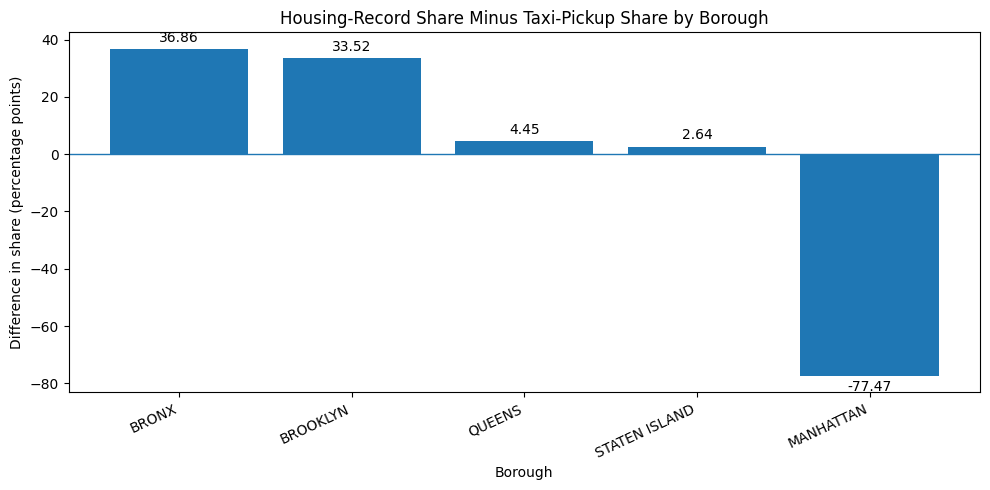

,borough,housing_record_share,taxi_pickup_share,share_gap_pp
0,BRONX,37.17,0.31,36.86
1,BROOKLYN,34.98,1.46,33.52
3,QUEENS,13.92,9.48,4.45
4,STATEN ISLAND,2.65,0.00,2.64
2,MANHATTAN,11.28,88.75,-77.47


In [59]:
# Q12: Compare the percentage-point gap between housing-record share and taxi-pickup share
share_data = integrated[["borough", "housing_records", "total_pickups"]].copy()
share_data["housing_record_share"] = share_data["housing_records"] / share_data["housing_records"].sum() * 100
share_data["taxi_pickup_share"] = share_data["total_pickups"] / share_data["total_pickups"].sum() * 100
share_data["share_gap_pp"] = share_data["housing_record_share"] - share_data["taxi_pickup_share"]
share_data = share_data.sort_values("share_gap_pp", ascending=False)
plt.figure(figsize=(10, 5))
bars = plt.bar(share_data["borough"], share_data["share_gap_pp"])
plt.axhline(0, linewidth=1)
plt.bar_label(bars, fmt="%.2f", padding=3)
plt.title("Housing-Record Share Minus Taxi-Pickup Share by Borough")
plt.xlabel("Borough")
plt.ylabel("Difference in share (percentage points)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()
display(share_data[["borough", "housing_record_share", "taxi_pickup_share", "share_gap_pp"]].round(2))


## 11. Website requirements checklist

The deployed website must include:
- [ ] Multiple dropdown filters using real dataset fields.
- [ ] Search mode that parses supported terms and applies filters.
- [ ] A **Generate Report** button that updates the visualizations from the active filters.
- [ ] Interactive charts with readable labels, units, and hover details.
- [ ] At least one visualization showing the relationship between the housing and transportation datasets.
- [ ] A story section with the question, actual findings, limitations, and NYC impact.
- [ ] Working public deployment and full source code in GitHub.

## 12. Findings, Limitations, and Impact

### Main Findings

- **Housing distribution:** The Bronx had the highest number of housing records associated with projects completed in 2024, with 323 records, followed by Brooklyn with 304. The Bronx also had the highest recorded total housing units, at 27,246.
- **Taxi activity:** Manhattan had by far the highest recorded yellow taxi activity in 2024, with 36,402,024 pickups, representing 88.75% of the five-borough total. Queens ranked second, with 3,887,094 pickups.
- **Monthly taxi patterns:** Taxi pickups were highest in October 2024, with 3,820,772 trips, and lowest in January, with 2,952,303 trips.
- **Differences between boroughs:** The Bronx and Brooklyn accounted for large shares of housing records but very small shares of taxi pickups. Manhattan showed the opposite pattern, with a high share of taxi pickups and a smaller share of housing records.
- **Relationship between housing and taxi activity:** The relationship differed by borough. Brooklyn showed a strong positive correlation (0.813), while the Bronx showed a very weak positive correlation (0.164). Staten Island showed a negative correlation (-0.333), based on 11 monthly observations. These results do not establish that housing completion records cause changes in taxi activity.

### Limitations

- **Housing completion dates:** A building's completion date does not necessarily indicate when residents moved in. In addition, a project's completion date may differ from the completion dates of individual buildings. Housing records and recorded total units should not automatically be interpreted as newly occupied homes or units newly created in 2024.
- **Taxi data coverage:** The taxi dataset measures recorded yellow taxi pickups only. It does not include all transportation methods, such as private cars, buses, subways, bicycles, or all ride-hailing services.
- **Geographic differences:** Taxi pickup locations are organized using taxi-zone identifiers, while the housing dataset uses borough and other geographic information. These geographic systems are not identical, and some taxi records were excluded because they were outside the five NYC boroughs or did not have a usable borough assignment.
- **Aggregation:** Aggregating data by borough and year can hide differences between neighborhoods and individual taxi zones. Monthly comparisons also provide only a limited number of observations.
- **Other influencing factors:** Taxi activity and housing development may be influenced by population, employment, tourism, public transportation access, weather, seasonality, and economic conditions. These factors were not controlled for in this analysis.
- **Correlation and causation:** Correlation indicates an association between two variables, not a cause-and-effect relationship. The results should be treated as exploratory findings rather than proof of a policy effect.
- **Data quality:** The datasets may contain missing information, incomplete geographic details, and unusual values. Cleaning and validation reduce some problems but cannot guarantee that all source data are complete or accurate.

### Potential Impact

The findings may help city planners, housing agencies, transportation planners, and community advocates understand how recorded housing activity and yellow taxi use differ across NYC boroughs. For example, the high concentration of taxi pickups in Manhattan and the larger share of housing records in the Bronx and Brooklyn may help identify areas for further investigation.

However, these results alone are not sufficient to make policy decisions. Further analysis should include population data, housing occupancy and affordability measures, public transportation usage, other transportation modes, neighborhood-level information, and more years of observations. These additional data would help determine whether the observed geographic differences reflect population size, travel demand, housing development patterns, or other factors.

### 13. Prompts Used

| Date | Prompt | Tool | Purpose | Output checked by |
|---|---|---|---|---|
| 28/10/2026 | Help interpret the relationship between housing completion records and taxi pickups by borough. | ChatGPT | Interpret Q11 correlations and write findings and limitations. | [Farida Nada] |
| 28/10/2026 | Help summarize the percentage shares of housing records and taxi pickups by borough. | ChatGPT | Interpret Q12 chart and explain share differences. | [Menna Kassem] |
| 28/10/2026 | Help write the overall findings, limitations, and potential impact based on the analysis results. | ChatGPT | Document the main findings and limitations of the project. | [Mariam Farahat] |

## 14. Team Contribution Log

| Member name / ID | Research questions | Visualizations | Cleaning / integration tasks | Website / documentation work |
|---|---|---|---|---|
| Farida Nada — 16007220 | Q1, Q2 | Charts for Q1, Q2 | Housing data cleaning and EDA | Findings and documentation |
| Menna Kassem — 16002792 | Q3, Q4 | Charts for Q3, Q4 | Taxi data cleaning and EDA | Research question documentation |
| Mariam Farahat — 16001862 | Q5, Q6 | Charts for Q5, Q6 | Taxi monthly aggregation | Findings and limitations |
| Adham Sameh — 16002948 | Q7, Q8 | Charts for Q7, Q8 | Data validation and cleaning | Website development |
| Habiba Salah — 16001573 | Q9, Q10 | Charts for Q9, Q10 | Housing and taxi data integration | Website and report functionality |
| Abdulrahman Ahmed — 16006387 | Q11, Q12 | Charts for Q11, Q12 | Integration validation and testing | README and deployment documentation |